# Prática guiada · Detecção de objetos com a YOLO

Nesta prática vamos percorrer **o ciclo completo** de um projeto de detecção com a YOLO: conhecer o dataset e o formato dos rótulos, treinar, entender o que foi salvo, ler as métricas, inspecionar os batches de treino e de validação, e fazer previsões.

Usamos o **African Wildlife**, um dataset que a YOLO baixa sozinha: fotos de animais na savana com caixas anotadas para 4 classes, **búfalo, elefante, rinoceronte e zebra**. Ele já vem dividido em treino (1.052 imagens), validação (225) e teste (227). O objetivo é que este notebook vire a **sua receita**: depois, você vai executá-lo de novo trocando **uma única linha**, a que diz qual é o dataset.

| Etapa | O que acontece |
| --- | --- |
| 0. Preparação | instalar a biblioteca e conferir o ambiente |
| 1. O dataset | baixar, ver a estrutura, o `data.yaml` e os rótulos `.txt` |
| 2. Antes de treinar | o que o modelo pré-treinado no COCO já sabe |
| 3. Treinar | uma chamada, com os hiperparâmetros da aula |
| 4. O que o treino salvou | a pasta de resultados, arquivo por arquivo |
| 5. As métricas do treino | losses, precisão, recall e mAP, época a época |
| 6. Os batches de treino | o que a rede realmente viu, com o mosaico |
| 7. A validação | real × previsto, curvas, matriz de confusão, métricas por classe e teste |
| 8. Prever imagens novas | usar o modelo e o efeito do limiar de confiança |
| 9. Guardar os resultados | copiar para o Google Drive |
| 10. Receita para o seu dataset | o que mudar para usar os seus dados |

**Como usar:** execute as células **em ordem**, lendo o texto antes de cada uma. Não é preciso mudar nada.

---
## 0. Preparação

**GPU:** no menu, *Ambiente de execução → Alterar o tipo de ambiente → GPU (T4)* → Salvar. Na detecção a GPU faz muita diferença: o treino desta prática leva cerca de 10 minutos na T4 e mais de uma hora na CPU. Faça isso **antes** de executar qualquer célula: trocar depois apaga o que já foi feito.

A instalação é uma linha. O `checks()` mostra as versões e se a GPU foi encontrada: procure por **CUDA** na saída. Se aparecer só **CPU**, volte e ligue a GPU.

In [ ]:
!pip install -q ultralytics

import ultralytics
ultralytics.checks()

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/235.7 GB disk)


A célula abaixo só define funções para mostrar pastas, imagens e tabelas. Basta executá-la.

In [ ]:
#@title Funções de apoio (não precisa ler) { display-mode: "form" }
import random, shutil, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml
import torch
from PIL import Image
from IPython.display import Image as MostrarImagem, display

warnings.filterwarnings('ignore')
random.seed(0)
TEM_GPU = torch.cuda.is_available()

# Só para exibir os nomes em português (o dataset continua com os nomes originais)
NOMES_LEGIVEIS = {'buffalo': 'búfalo', 'elephant': 'elefante', 'rhino': 'rinoceronte', 'zebra': 'zebra'}
def legivel(nome):
    return NOMES_LEGIVEIS.get(nome, nome)

CORES = ['#1767A6', '#C04E14', '#2E7D32', '#5B3E99', '#A3262F', '#0E7C86']
EXTENSOES = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}

def imagens_da_pasta(pasta):
    return sorted(p for p in Path(pasta).iterdir() if p.suffix.lower() in EXTENSOES)

def rotulo_da_imagem(imagem):
    # A YOLO acha o rótulo trocando /images/ por /labels/ e a extensão por .txt
    partes = list(Path(imagem).parts)
    i = len(partes) - 1 - partes[::-1].index('images')
    partes[i] = 'labels'
    return Path(*partes).with_suffix('.txt')

def ler_rotulo(arquivo_txt):
    # Cada linha: classe x_centro y_centro largura altura (normalizados de 0 a 1)
    if not Path(arquivo_txt).exists():
        return []
    linhas = [l.split() for l in Path(arquivo_txt).read_text().splitlines() if l.strip()]
    return [(int(l[0]), *map(float, l[1:5])) for l in linhas]

def desenhar_rotulos(ax, imagem, nomes):
    img = Image.open(imagem).convert('RGB')
    L, A = img.size
    ax.imshow(img); ax.axis('off')
    for classe, xc, yc, w, h in ler_rotulo(rotulo_da_imagem(imagem)):
        x1, y1 = (xc - w / 2) * L, (yc - h / 2) * A       # de centro normalizado para canto em pixels
        cor = CORES[classe % len(CORES)]
        ax.add_patch(patches.Rectangle((x1, y1), w * L, h * A, fill=False, edgecolor=cor, linewidth=2.5))
        ax.text(x1, y1, legivel(nomes[classe]), color='white', fontsize=8, fontweight='bold',
                va='bottom', bbox=dict(facecolor=cor, edgecolor='none', pad=1.5))

def arvore(pasta, niveis=2, por_nivel=3, _prefixo='', _nivel=0):
    # Mostra a estrutura de pastas, com só alguns itens por nível
    if _nivel == 0:
        print(str(pasta) + '/')
    itens = sorted(Path(pasta).iterdir())
    pastas = [p for p in itens if p.is_dir()]
    arquivos = [p for p in itens if p.is_file()]
    for p in pastas[:por_nivel]:
        print(f'{_prefixo}├── {p.name}/')
        if _nivel + 1 < niveis:
            arvore(p, niveis, por_nivel, _prefixo + '│   ', _nivel + 1)
    if len(pastas) > por_nivel:
        print(f'{_prefixo}├── ... (+{len(pastas) - por_nivel} pastas)')
    if arquivos:
        nomes = ', '.join(a.name for a in arquivos[:3])
        print(f'{_prefixo}└── {nomes}{" ..." if len(arquivos) > 3 else ""} ({len(arquivos)} arquivos)')

def mostrar_arquivos(pasta, padrao, largura=700):
    arquivos = sorted(Path(pasta).glob(padrao))
    if not arquivos:
        print(f'Nenhum arquivo "{padrao}" encontrado em {pasta}.')
    for a in arquivos:
        print(a.name)
        display(MostrarImagem(filename=str(a), width=largura))

def mostrar_resultados(resultados, titulos, colunas=3, tamanho=5):
    # Mostra imagens com as caixas previstas, usando o desenho da própria YOLO
    linhas = int(np.ceil(len(resultados) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=(colunas * tamanho, linhas * tamanho * 0.8))
    for ax in np.atleast_1d(eixos).ravel():
        ax.axis('off')
    for ax, r, titulo in zip(np.atleast_1d(eixos).ravel(), resultados, titulos):
        ax.imshow(r.plot()[..., ::-1]); ax.set_title(titulo, fontsize=10)
    plt.tight_layout(); plt.show()

print('Pronto. GPU encontrada:', TEM_GPU)

Pronto. GPU encontrada: True


---
## 1. O dataset

Na detecção, o argumento `data=` recebe **um arquivo `data.yaml`**, e não uma pasta como na classificação. Ele pode ser:

- **O nome de um dataset que a YOLO conhece**, como `"coco8.yaml"` ou `"african-wildlife.yaml"`. Ela baixa sozinha na primeira vez.
- **O caminho do `data.yaml` de um dataset seu**, como `"/content/meu_dataset/data.yaml"`.

**Depois, esta é a linha que você troca.**

In [ ]:
DATASET = "african-wildlife.yaml"          # o seu: "/content/meu_dataset/data.yaml"

### 1.1 Baixar e localizar

Na classificação o dataset era baixado durante o treino. Aqui vamos baixá-lo **antes**, para conhecer o formato primeiro. A função `check_det_dataset` faz o que o treino faria: lê o `data.yaml`, baixa o dataset se for preciso e devolve onde estão as imagens de cada divisão. Ele fica nos **arquivos temporários** do Colab, numa pasta `datasets/`, que você pode abrir no **ícone de pasta** do painel à esquerda.

In [ ]:
from ultralytics.data.utils import check_det_dataset

info = check_det_dataset(DATASET)
pasta_dataset = Path(info['path'])
NOMES = info['names']                          # {0: 'buffalo', 1: 'elephant', ...}

print('O dataset está em:', pasta_dataset)
print('Classes:', {i: legivel(n) for i, n in NOMES.items()})


WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 1.0Kfiles/s 2.9s
Dataset download success ✅ (4.7s), saved to /content/datasets

O dataset está em: /content/datasets/african-wildlife
Classes: {0: 'búfalo', 1: 'elefante', 2: 'rinoceronte', 3: 'zebra'}


### 1.2 A estrutura de pastas

Este é o formato da YOLO para detecção: duas pastas irmãs, `images/` e `labels/`, cada uma com as **mesmas** subpastas `train/`, `val/` e `test/`.

In [ ]:
arvore(pasta_dataset, niveis=3, por_nivel=3)

/content/datasets/african-wildlife/
├── images/
│   ├── test/
│   │   └── 1 (103).jpg, 1 (121).jpg, 1 (128).jpg ... (227 arquivos)
│   ├── train/
│   │   └── 1 (10).jpg, 1 (100).jpg, 1 (101).jpg ... (1052 arquivos)
│   ├── val/
│   │   └── 1 (1).jpg, 1 (102).jpg, 1 (111).jpg ... (225 arquivos)
├── labels/
│   ├── test/
│   │   └── 1 (103).txt, 1 (121).txt, 1 (128).txt ... (227 arquivos)
│   ├── train/
│   │   └── 1 (10).txt, 1 (100).txt, 1 (101).txt ... (1052 arquivos)
│   ├── val/
│   │   └── 1 (1).txt, 1 (102).txt, 1 (111).txt ... (225 arquivos)
└── LICENSE.txt, african-wildlife.yaml (2 arquivos)


**O que observar:**

- Cada imagem em `images/train/` tem um `.txt` **com o mesmo nome** em `labels/train/`. É assim que a YOLO acha o rótulo: troca `images` por `labels` no caminho e a extensão por `.txt`.
- Os arquivos `.cache` são criados pela YOLO para carregar os rótulos mais rápido nas próximas vezes. **Se você corrigir algum rótulo, apague o `.cache`.**
- Na classificação, a pasta dizia a classe. Aqui uma imagem pode ter vários animais de classes diferentes, então a classe vai **dentro** do `.txt`.

### 1.3 O `data.yaml`

O arquivo que o `data=` recebe. Ele diz onde está o dataset (`path`), onde estão as imagens de cada divisão (`train`, `val`, `test`, relativas ao `path`) e o nome de cada número de classe (`names`).

In [ ]:
print(open(info['yaml_file']).read())

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# African Wildlife dataset by Ultralytics
# Documentation: https://docs.ultralytics.com/datasets/detect/african-wildlife
# Example usage: yolo train data=african-wildlife.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── african-wildlife ← downloads here (100 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: african-wildlife # dataset root dir
train: images/train # train images (relative to 'path') 1052 images
val: images/val # val images (relative to 'path') 225 images
test: images/test # test images (relative to 'path') 227 images

# Classes
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra

# Download script/URL (optional)
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip



**O que observar:** as linhas que começam com `#` são comentários. Aqui o `path` é só `african-wildlife`, um caminho relativo à pasta `datasets/` da YOLO, porque o dataset é dela. **No seu `data.yaml`, use o caminho completo**, como `/content/meu_dataset`, e lembre de atualizá-lo se mudar o dataset de lugar.

### 1.4 Um rótulo `.txt` por dentro

Uma linha por objeto, com cinco números separados por espaço:

`classe  x_centro  y_centro  largura  altura`

A classe é o índice do `names` (começa em 0). As outras quatro são **normalizadas**: divididas pela largura e pela altura da imagem, ficando entre 0 e 1. O `x` e o `y` são o **centro** da caixa, não o canto.

In [ ]:
imagens_treino = imagens_da_pasta(Path(info['train']))
com_varios = [p for p in imagens_treino if len(ler_rotulo(rotulo_da_imagem(p))) >= 3]
exemplo = random.choice(com_varios)              # uma imagem com 3 ou mais animais

print('Imagem:', exemplo.name)
print('Rótulo:', rotulo_da_imagem(exemplo).name, '\n')
print(rotulo_da_imagem(exemplo).read_text())

L, A = Image.open(exemplo).size
print(f'Tamanho da imagem: {L} × {A} pixels\n')
for classe, xc, yc, w, h in ler_rotulo(rotulo_da_imagem(exemplo)):
    print(f'{legivel(NOMES[classe]):12s} centro em ({xc * L:.0f}, {yc * A:.0f}) px · caixa de {w * L:.0f} × {h * A:.0f} px')

Imagem: 2 (89).jpg
Rótulo: 2 (89).txt 

1 0.183594 0.503125 0.364063 0.710417
1 0.450000 0.481250 0.378125 0.612500
1 0.714063 0.591667 0.262500 0.358333

Tamanho da imagem: 640 × 480 pixels

elefante     centro em (118, 242) px · caixa de 233 × 341 px
elefante     centro em (288, 231) px · caixa de 242 × 294 px
elefante     centro em (457, 284) px · caixa de 168 × 172 px


A última parte da célula desfaz a normalização: multiplica `x` e a largura pela largura da imagem, e `y` e a altura pela altura. Desenhando as caixas a partir do `.txt`, sem modelo nenhum, vemos exatamente o que foi anotado:

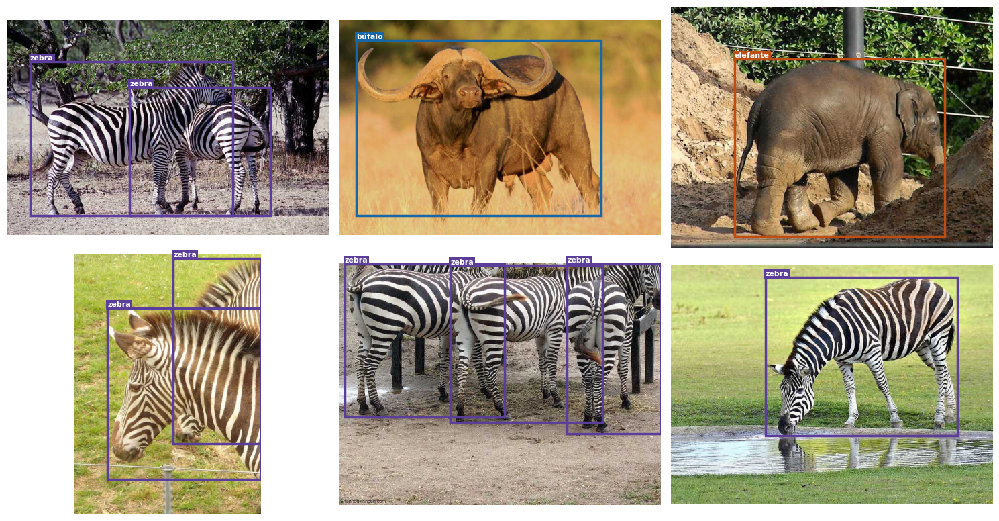

In [ ]:
amostra = random.sample(imagens_treino, 6)
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for ax, img in zip(eixos.ravel(), amostra):
    desenhar_rotulos(ax, img, NOMES)
plt.tight_layout(); plt.show()

**Esta conferência vale ouro no seu dataset.** Antes de treinar, desenhe algumas imagens a partir dos `.txt`: se as caixas aparecerem deslocadas, gigantes ou na classe errada, o problema está na exportação dos rótulos, e o treino não vai consertar isso.

### 1.5 Quantas imagens e quantas caixas

Na detecção, o equilíbrio entre classes se mede em **caixas** (objetos), não só em imagens: uma única foto pode ter dez zebras.

In [ ]:
linhas = []
for divisao in ['train', 'val', 'test']:
    if not info.get(divisao):
        continue
    imagens = imagens_da_pasta(Path(info[divisao]))
    caixas = Counter()
    sem_rotulo = 0
    for img in imagens:
        rot = ler_rotulo(rotulo_da_imagem(img))
        sem_rotulo += (len(rot) == 0)
        caixas.update(legivel(NOMES[c]) for c, *_ in rot)
    linha = {'divisão': divisao, 'imagens': len(imagens), 'imagens de fundo': sem_rotulo}
    linha.update({f'caixas · {legivel(n)}': caixas[legivel(n)] for n in NOMES.values()})
    linhas.append(linha)

tabela = pd.DataFrame(linhas).set_index('divisão')
display(tabela)

,imagens,imagens de fundo,caixas · búfalo,caixas · elefante,caixas · rinoceronte,caixas · zebra
divisão,,,,,,
train,1052,0,399,558,399,575
val,225,0,89,91,85,114
test,227,0,66,99,75,135


**O que observar:**

- As quatro classes têm quantidades de caixas parecidas, e as proporções se repetem em treino, validação e teste: a divisão está equilibrada.
- **Imagens de fundo** são imagens sem nenhum objeto (sem `.txt` ou com o `.txt` vazio). Elas ensinam o modelo a não inventar caixas. Aqui há poucas ou nenhuma.

---
## 2. Antes de treinar: o que o modelo sabe

O `yolo26n.pt` é **pré-treinado no COCO**, um dataset com 80 classes do dia a dia. Entre elas estão **elefante e zebra**, mas **não** búfalo nem rinoceronte. Vamos ver o que ele encontra em algumas imagens de validação, antes de qualquer treino.

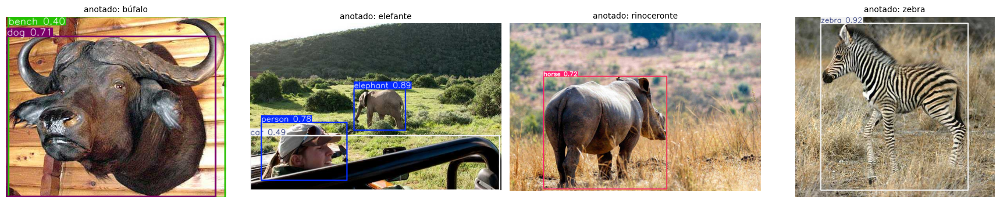

1 (80).jpg   → {'dog': 1, 'bench': 1}
2 (99).jpg   → {'elephant': 1, 'person': 1, 'car': 1}
3 (99).jpg   → {'horse': 1, 'cow': 1}
4 (211).jpg  → {'zebra': 1}


In [ ]:
from ultralytics import YOLO

pre_treinado = YOLO("yolo26n.pt")                # baixa os pesos na primeira vez

imagens_val = imagens_da_pasta(Path(info['val']))
amostra_val = []
for classe in NOMES:                             # uma imagem de cada classe
    candidatas = [p for p in imagens_val if {c for c, *_ in ler_rotulo(rotulo_da_imagem(p))} == {classe}]
    if candidatas:                               # classe sem imagem só dela na validação: pula
        amostra_val.append(random.choice(candidatas))

resultados = pre_treinado(amostra_val, verbose=False)
titulos = [f'anotado: {legivel(NOMES[ler_rotulo(rotulo_da_imagem(p))[0][0]])}' for p in amostra_val]
mostrar_resultados(resultados, titulos, colunas=4, tamanho=4.5)

for p, r in zip(amostra_val, resultados):
    achou = Counter(r.names[int(c)] for c in r.boxes.cls)
    print(f'{p.name:12s} → {dict(achou) if achou else "nada"}')

**O que observar:** o modelo já sabe **achar animais** e acerta elefantes e zebras, que estão no COCO. Mas chama búfalo de *cow* (vaca) e rinoceronte de *elephant*, *cow* ou não acha nada: ele não conhece essas classes.

O treino a seguir é o *transfer learning*: a rede reaproveita o que aprendeu sobre bordas, formas e "coisas que parecem animais", e a saída de 80 classes é trocada pelas 4 do nosso `data.yaml`. Na saída do treino, procure a linha **"Remapped 2/4 cls head rows from pretrained weights by class name"**: a YOLO percebeu que *elephant* e *zebra* têm o mesmo nome no COCO e aproveitou o que já sabia delas.

---
## 3. Treinar

Uma única chamada treina o modelo. Cada argumento é um hiperparâmetro que já vimos na aula:

| Argumento | Valor | O que faz |
| --- | --- | --- |
| `model` | `yolo26n.pt` | a menor YOLO26 de detecção, **pré-treinada no COCO** (sem o sufixo `-cls`) |
| `data` | `DATASET` | o `data.yaml` do dataset |
| `epochs` | 30 | quantas vezes a rede passa por todo o conjunto de treino |
| `imgsz` | 640 | o tamanho em que as imagens entram na rede (os modelos de detecção foram pré-treinados em 640) |
| `batch` | 16 | quantas imagens por atualização dos pesos |
| `patience` | 10 | early stopping: para se a validação passar 10 épocas sem melhorar (o padrão é 100) |
| `seed` | 0 | fixa a aleatoriedade, para o resultado ser reproduzível |
| `project`, `name` | `"aula_yolo"`, `"treino"` | o nome da pasta onde salvar |

**E o espelhamento?** Por padrão, a YOLO espelha metade das imagens na horizontal (`fliplr=0.5`). Para animais isso faz sentido: uma zebra virada para a esquerda continua sendo zebra. **No seu dataset, pense se espelhar faz sentido**: para texto, placas ou setas, use `fliplr=0.0`.

**No Colab não é preciso o `main()`.** Num arquivo `.py` no seu computador, coloque o treino dentro de `def main():` e chame com `if __name__ == "__main__": main()`, como no manual.

**Lendo a saída enquanto treina:**

- **"Remapped ... by class name"** e **"Transferred ... items"**: os pesos pré-treinados foram carregados.
- **"optimizer=auto found, ignoring lr0"**: o otimizador está no automático e escolhe o learning rate sozinho.
- **"Plotting labels to ... labels.jpg"**: o gráfico com as caixas por classe (etapa 6).
- **A cada época**, uma barra com as losses (`box_loss`, `cls_loss`, `l1_loss`) e, em seguida, a validação com **P, R, mAP50 e mAP50-95**.
- **"Closing dataloader mosaic"**: nas últimas 10 épocas o mosaico é desligado (etapa 6).
- No fim, a YOLO valida o `best.pt` e mostra a tabela **por classe**, e a mensagem **"Results saved to ..."** diz onde ficou tudo.

**As colunas da barra de treino** (valores de exemplo):

```
Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
 1/30      2.1G      1.043      4.125      0.022         12        640
```

| Coluna | O que é |
| --- | --- |
| `Epoch` | a época atual e o total pedido |
| `GPU_mem` | quanta memória da GPU o treino está usando. Se faltar memória, diminua o `batch` |
| `box_loss` | o erro de **sobreposição** da caixa (detalhes abaixo) |
| `cls_loss` | o erro na **classe** de cada caixa |
| `l1_loss` | o erro de **cada borda** da caixa |
| `Instances` | quantas caixas anotadas havia no último batch |
| `Size` | o tamanho em que as imagens entram na rede (`imgsz`) |

**As três losses, uma por uma.** A loss total que a rede tenta diminuir é a soma das três, cada uma com um peso. Elas medem coisas diferentes:

- **`box_loss`: a caixa está no lugar?** Compara a caixa prevista com a anotada pelo **IoU**, o mesmo da aula: a loss é **1 − IoU**. Caixa idêntica à anotada: IoU 1, loss 0. Caixa que não encosta na anotada: IoU 0, loss 1. A YOLO usa uma versão do IoU chamada **CIoU**, que também penaliza centros distantes e proporções diferentes (uma caixa "deitada" quando o objeto está "em pé"). Isso ajuda a caixa a se aproximar mesmo quando ainda não há sobreposição.
- **`l1_loss`: cada borda está no lugar?** A rede descreve cada caixa por quatro distâncias, de um ponto dentro do objeto até as bordas **esquerda, topo, direita e base**. A `l1_loss` é a diferença média, em valor absoluto, entre essas distâncias e as da caixa anotada, divididas pelo tamanho da imagem. Enquanto a `box_loss` olha a sobreposição como um todo, a `l1_loss` cobra borda por borda. Nas YOLOs anteriores (v8, v11), este papel era da **`dfl_loss`**; a YOLO26 a trocou pela L1, por isso tutoriais antigos mostram `dfl_loss` no lugar.
- **`cls_loss`: a classe está certa?** Para cada caixa, a rede dá uma pontuação para cada uma das 4 classes. A `cls_loss` (uma *binary cross-entropy*, parente da cross-entropy da classificação) cobra pontuação alta na classe certa e baixa nas outras. Ela também ensina a rede a dar pontuação baixa **onde não há objeto**, e é por isso que costuma ser a maior das três no começo do treino.

**Como ler:** as três devem **cair** ao longo das épocas, e não precisam cair no mesmo ritmo. `box_loss` e `l1_loss` caindo: as caixas estão ficando mais justas, o que puxa o **mAP50-95** para cima. `cls_loss` caindo: o modelo está separando melhor búfalo de rinoceronte e animal de fundo. Os valores absolutos não importam muito; o que importa é a **tendência** e a comparação com as mesmas losses na validação (etapa 5).

In [ ]:
model = YOLO("yolo26n.pt")         # pré-treinado no COCO

model.train(
    data=DATASET,
    epochs=20,
    imgsz=640,
    batch=32,
    patience=10,
    seed=0,
    project="aula_yolo",
    name="treino",
    exist_ok=True,           # se treinar de novo, sobrescreve a mesma pasta
)

pasta_treino = Path(model.trainer.save_dir)
print('\nO treino foi salvo em:', pasta_treino)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treino, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

---
## 4. O que o treino salvou

Tudo do treino fica numa única pasta (aqui, `runs/detect/aula_yolo/treino/`):

In [ ]:
arvore(pasta_treino, niveis=2, por_nivel=30)

/content/runs/detect/aula_yolo/treino/
├── weights/
│   └── best.pt, last.pt (2 arquivos)
└── BoxF1_curve.png, BoxPR_curve.png, BoxP_curve.png ... (22 arquivos)


| Arquivo | O que é |
| --- | --- |
| `weights/best.pt` | o modelo da **melhor época** na validação. É ele que se usa depois |
| `weights/last.pt` | o modelo da **última** época (útil para continuar um treino interrompido) |
| `results.csv` / `results.png` | as métricas de cada época, em tabela e em gráfico |
| `labels.jpg` | **novo:** quantas caixas há de cada classe e onde e de que tamanho elas ficam |
| `train_batch*.jpg` | exemplos de batches **de treino**, como a rede os viu |
| `val_batch*_labels.jpg` / `val_batch*_pred.jpg` | batches de validação com as caixas **anotadas** e com as **previstas** |
| `BoxPR_curve.png` | **novo:** a curva precisão × recall de cada classe (a área sob ela é o AP) |
| `BoxF1_curve.png`, `BoxP_curve.png`, `BoxR_curve.png` | **novo:** F1, precisão e recall conforme o limiar de confiança |
| `confusion_matrix*.png` | a matriz de confusão, agora com a classe **background** (fundo) |
| `args.yaml` | **todos** os argumentos usados, inclusive os padrões que você não escreveu |

Vamos abrir cada um nas próximas etapas.

---
## 5. As métricas do treino

### 5.1 A tabela `results.csv`

Uma linha por época. As colunas:

| Coluna | Significado |
| --- | --- |
| `epoch`, `time` | o número da época e o tempo acumulado, em segundos |
| `train/box_loss` | o erro na **posição e no tamanho** das caixas (quanto menor, mais justas) |
| `train/cls_loss` | o erro na **classe** de cada caixa |
| `train/l1_loss` | outra medida do erro das coordenadas da caixa, usada pela YOLO26 |
| `metrics/precision(B)` | a **precisão** na validação: das caixas desenhadas, quantas estavam certas |
| `metrics/recall(B)` | o **recall**: dos animais anotados, quantos foram encontrados |
| `metrics/mAP50(B)` | o **mAP** com IoU ≥ 0,50 |
| `metrics/mAP50-95(B)` | o **mAP** médio nos limiares de IoU de 0,50 a 0,95: **a métrica principal** |
| `val/box_loss`, `val/cls_loss`, `val/l1_loss` | as mesmas losses, na validação |
| `lr/pg0`, `lr/pg1`, `lr/pg2` | o **learning rate** de cada grupo de pesos |

O `(B)` quer dizer *box*: métricas das caixas. (Os nomes podem variar um pouco entre versões; as células abaixo procuram as colunas pelo nome.)

In [ ]:
res = pd.read_csv(pasta_treino / 'results.csv')
res.columns = [c.strip() for c in res.columns]
display(res.round(4))

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
0,1,39.5190,0.8796,14.9646,0.0130,0.7875,0.7958,0.8466,0.6765,0.8598,8.0943,0.0199,0.0004,0.0004,0.0004
1,2,57.7066,0.9099,2.6716,0.0136,0.8532,0.7605,0.8534,0.6108,0.9762,2.0750,0.0237,0.0008,0.0008,0.0008
2,3,76.2132,0.9764,1.4727,0.0147,0.7660,0.7616,0.8221,0.5768,1.0487,1.5850,0.0255,0.0011,0.0011,0.0011
3,4,94.4410,0.9734,1.2335,0.0150,0.8166,0.7748,0.8670,0.6390,0.9798,1.3142,0.0230,0.0011,0.0011,0.0011
4,5,114.0920,0.9624,1.1481,0.0142,0.8524,0.7752,0.8625,0.6419,1.0219,1.2602,0.0257,0.0010,0.0010,0.0010
5,6,132.2060,0.9543,1.0263,0.0144,0.8998,0.8202,0.9046,0.6781,1.0025,1.1225,0.0249,0.0009,0.0009,0.0009
6,7,149.9170,0.9044,0.9382,0.0137,0.9344,0.8343,0.9186,0.7004,0.9768,0.9153,0.0247,0.0009,0.0009,0.0009
7,8,168.4590,0.8870,0.8721,0.0137,0.9261,0.8553,0.9385,0.7434,0.8691,0.8079,0.0210,0.0008,0.0008,0.0008
8,9,186.8730,0.8511,0.8383,0.0129,0.9684,0.8313,0.9425,0.7604,0.8664,0.7640,0.0212,0.0008,0.0008,0.0008
9,10,204.7440,0.8468,0.8192,0.0126,0.9096,0.8584,0.9302,0.7428,0.8746,0.8167,0.0212,0.0007,0.0007,0.0007


### 5.2 As curvas

Quatro gráficos: as **losses** de treino e de validação, **precisão e recall**, os dois **mAPs** e o **learning rate**.

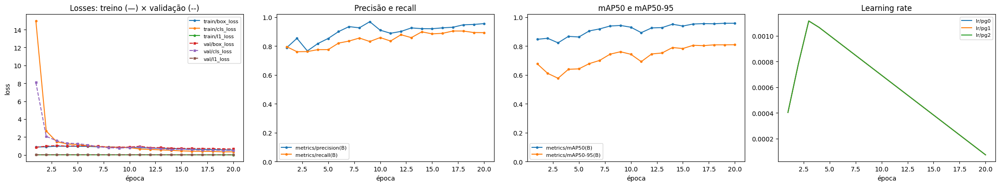

In [ ]:
col_treino = [c for c in res.columns if c.startswith('train/')]
col_val = [c for c in res.columns if c.startswith('val/')]
col_pr = [c for c in res.columns if 'precision' in c or 'recall' in c]
col_map = [c for c in res.columns if 'mAP' in c]
col_lr = [c for c in res.columns if c.startswith('lr')]

fig, eixos = plt.subplots(1, 4, figsize=(22, 4.2))
for c in col_treino:
    eixos[0].plot(res['epoch'], res[c], 'o-', ms=3, label=c)
for c in col_val:
    eixos[0].plot(res['epoch'], res[c], 's--', ms=3, label=c)
for c in col_pr:
    eixos[1].plot(res['epoch'], res[c], 'o-', ms=3, label=c)
for c in col_map:
    eixos[2].plot(res['epoch'], res[c], 'o-', ms=3, label=c)
for c in col_lr:
    eixos[3].plot(res['epoch'], res[c], label=c)
eixos[0].set(xlabel='época', ylabel='loss', title='Losses: treino (—) × validação (--)')
eixos[1].set(xlabel='época', title='Precisão e recall', ylim=(0, 1.02))
eixos[2].set(xlabel='época', title='mAP50 e mAP50-95', ylim=(0, 1.02))
eixos[3].set(xlabel='época', title='Learning rate')
for ax in eixos:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Como ler:**

- **Losses de treino e de validação caindo juntas:** a rede está aprendendo. Treino caindo e validação subindo: **overfitting**. As duas ainda caindo no fim: dava para treinar mais.
- **`box_loss` × `cls_loss`:** a primeira mede se as caixas estão no lugar; a segunda, se a classe está certa. Elas podem melhorar em ritmos diferentes.
- **Precisão e recall** oscilam bastante de uma época para outra, porque dependem de um limiar de confiança.
- **mAP50 sempre acima do mAP50-95:** é esperado, porque o mAP50-95 exige caixas mais justas. A distância entre os dois diz se o modelo acha os animais mas desenha caixas frouxas.
- **Learning rate:** começa pequeno (*warmup*) e depois **diminui** até o fim: passos maiores no começo, passos finos no final.
- **Repare nas últimas 10 épocas:** é quando o mosaico desliga, e as losses costumam dar um salto para baixo.

### 5.3 A melhor época

In [ ]:
col_m = [c for c in res.columns if 'mAP50-95' in c][0]
col_m50 = [c for c in res.columns if 'mAP50' in c and '95' not in c][0]
melhor_linha = res.loc[res[col_m].idxmax()]

print(f'Épocas treinadas         : {len(res)} (de 30 pedidas)')
print(f'Melhor mAP50-95          : {melhor_linha[col_m]:.3f}, na época {int(melhor_linha["epoch"])}')
print(f'mAP50 nessa época        : {melhor_linha[col_m50]:.3f}')
print(f'mAP50-95 na última época : {res[col_m].iloc[-1]:.3f}')

Épocas treinadas         : 20 (de 30 pedidas)
Melhor mAP50-95          : 0.809, na época 20
mAP50 nessa época        : 0.958
mAP50-95 na última época : 0.809


Se o treino parou antes das 30 épocas, foi o **early stopping** (`patience=10`). O `best.pt` guarda o modelo da melhor época, escolhida principalmente pelo **mAP50-95** na validação.

### 5.4 O gráfico pronto da YOLO

A YOLO também salva todas essas curvas num único gráfico, o `results.png`:

results.png


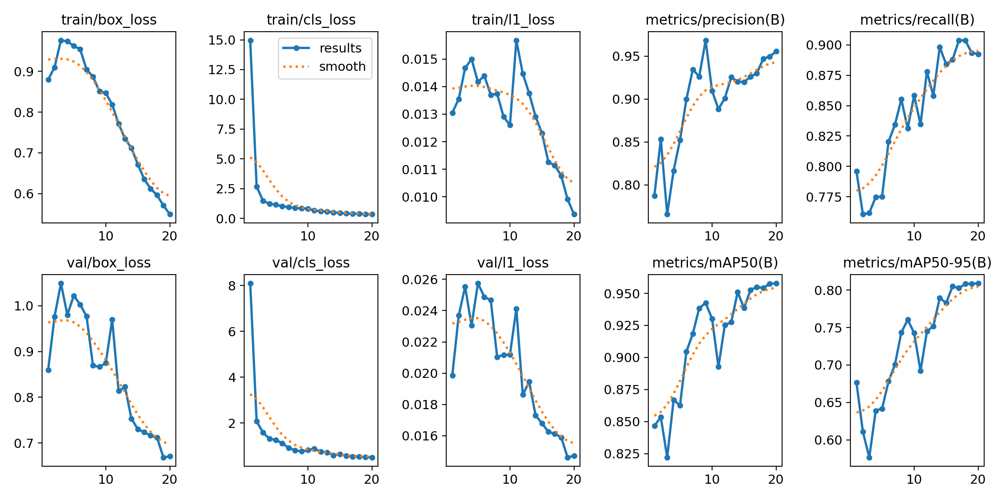

In [ ]:
mostrar_arquivos(pasta_treino, 'results.png', largura=1000)

---
## 6. Os batches de treino

### 6.1 O que a rede viu: o mosaico

Durante as primeiras épocas, a YOLO salva alguns **batches de treino** (`train_batch*.jpg`), já **depois do aumento de dados**. Na detecção, o aumento mais visível é o **mosaico**: quatro imagens de treino recortadas e coladas numa só, com as caixas acompanhando.

train_batch0.jpg


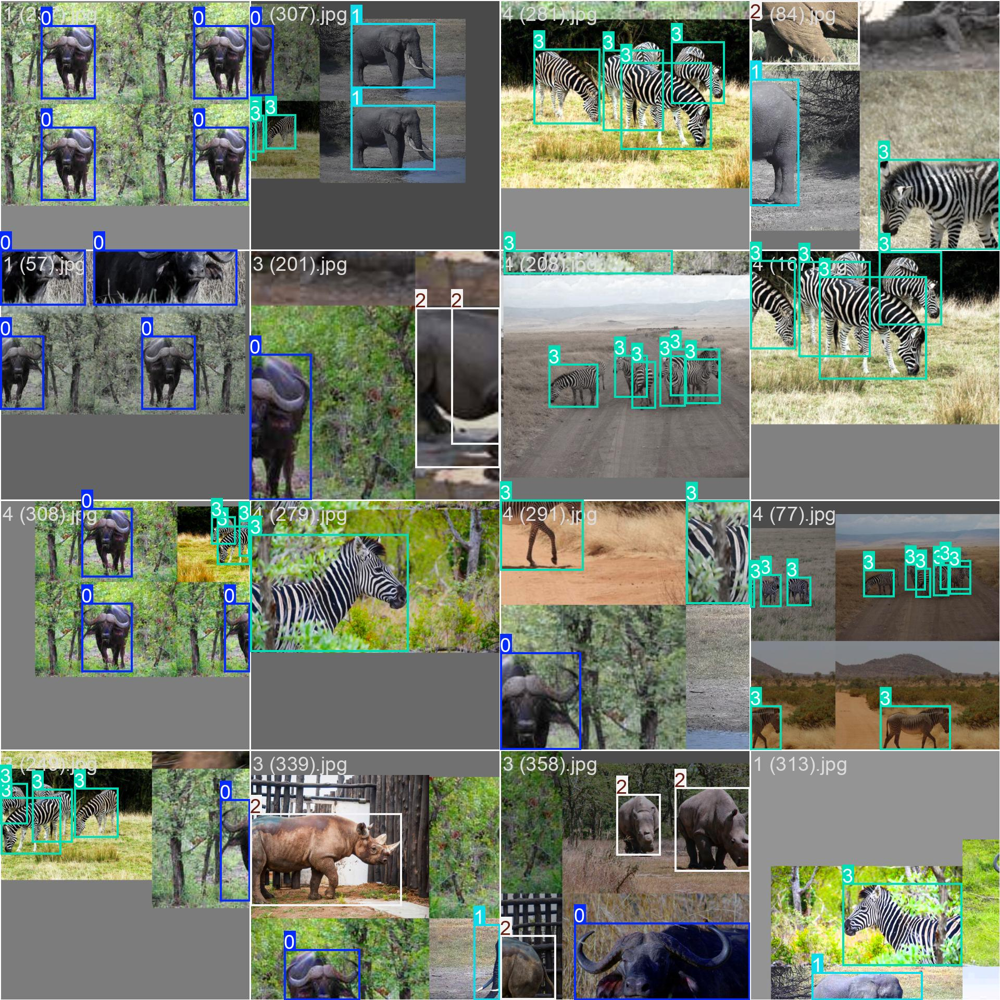

train_batch1.jpg


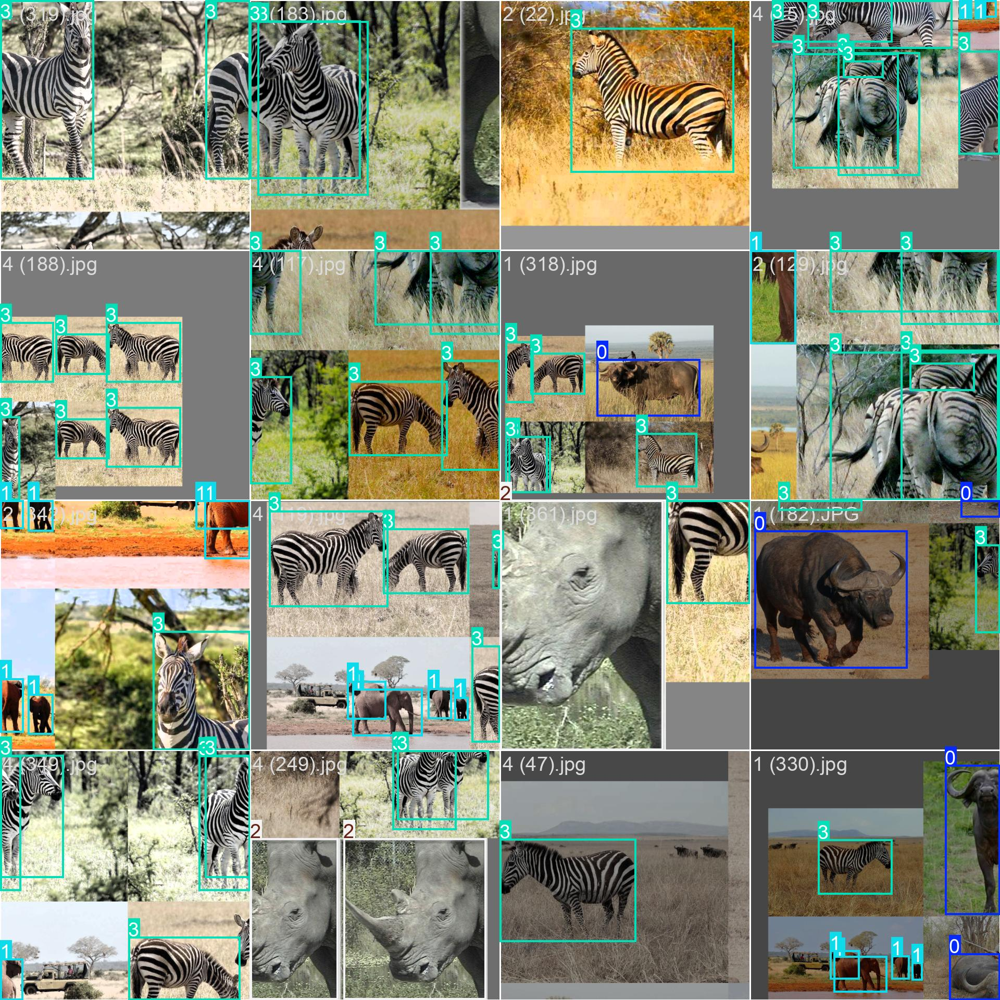

train_batch2.jpg


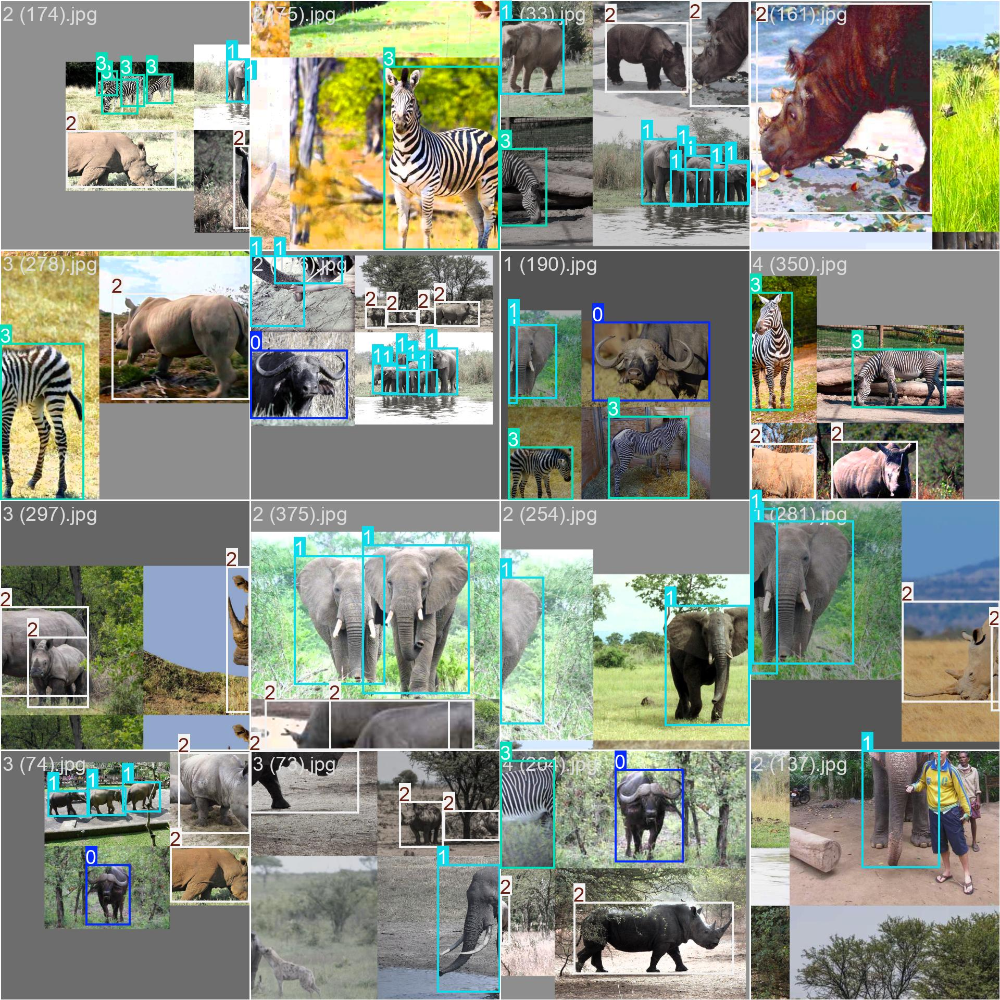

train_batch330.jpg


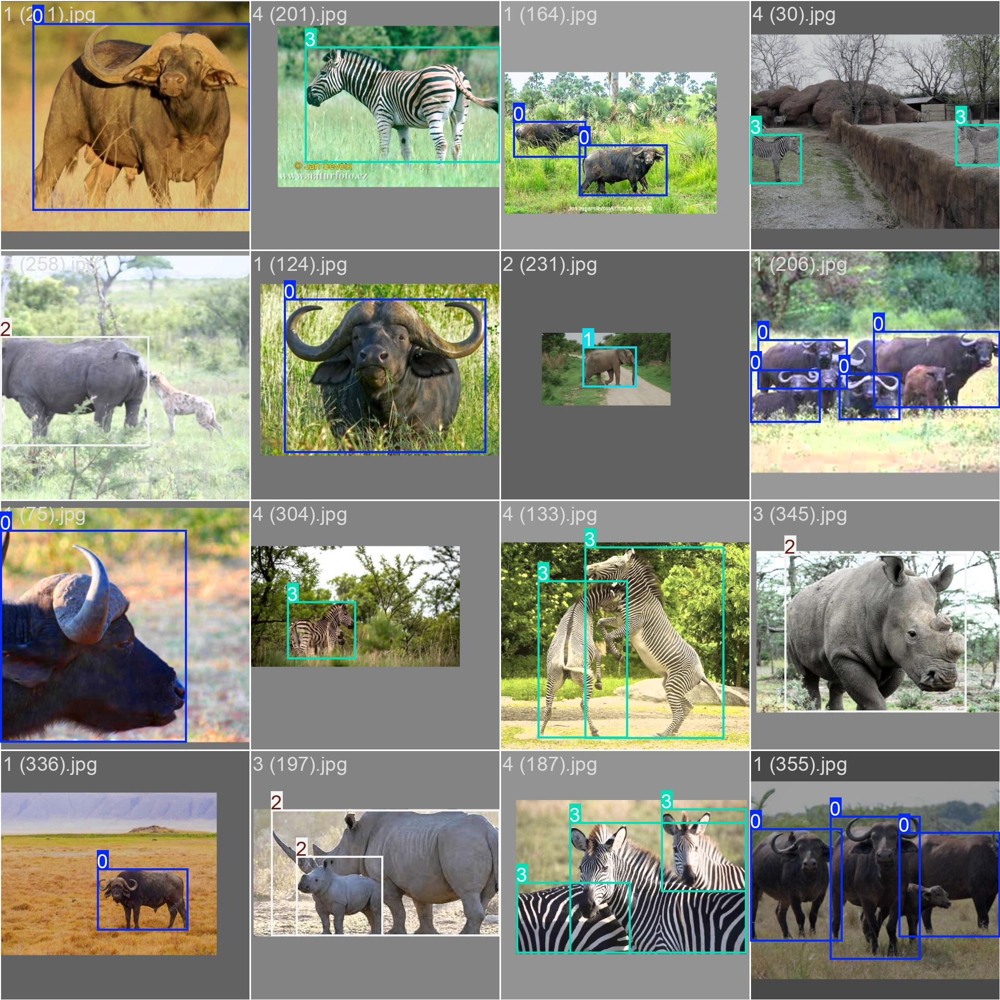

train_batch331.jpg


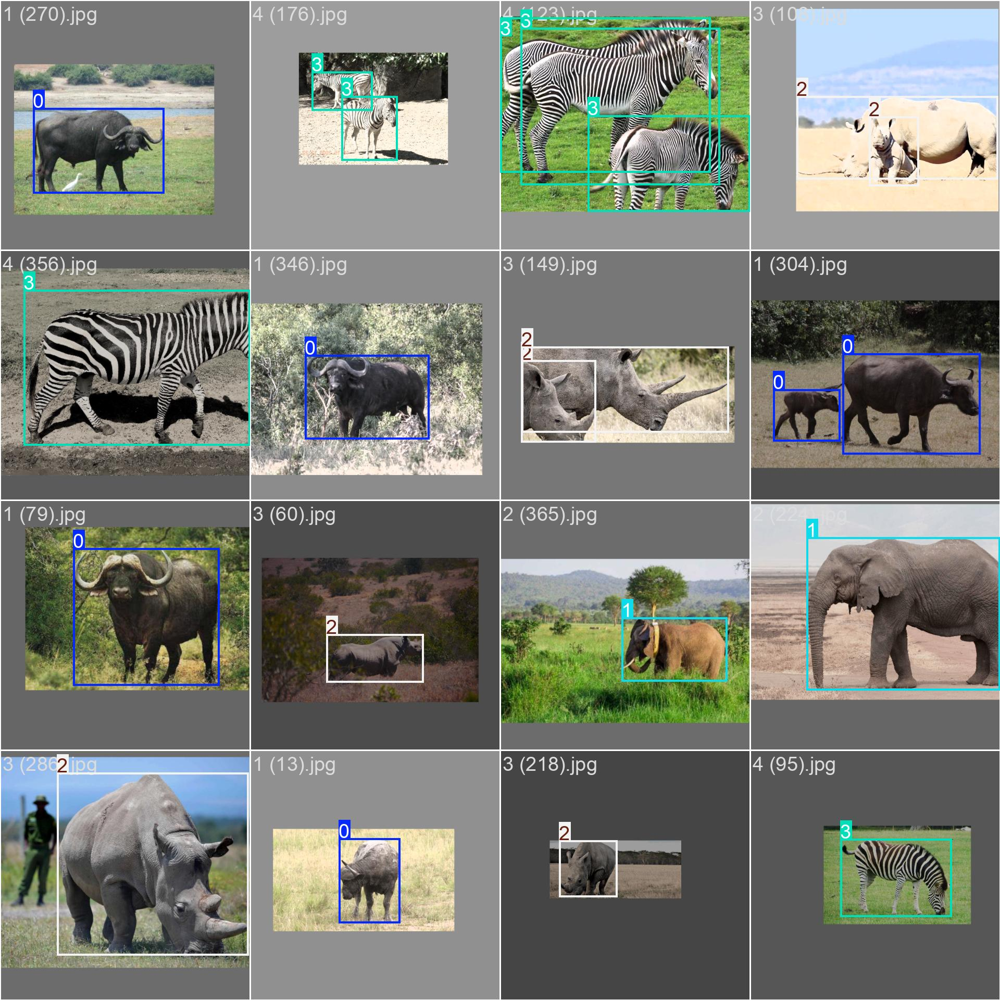

train_batch332.jpg


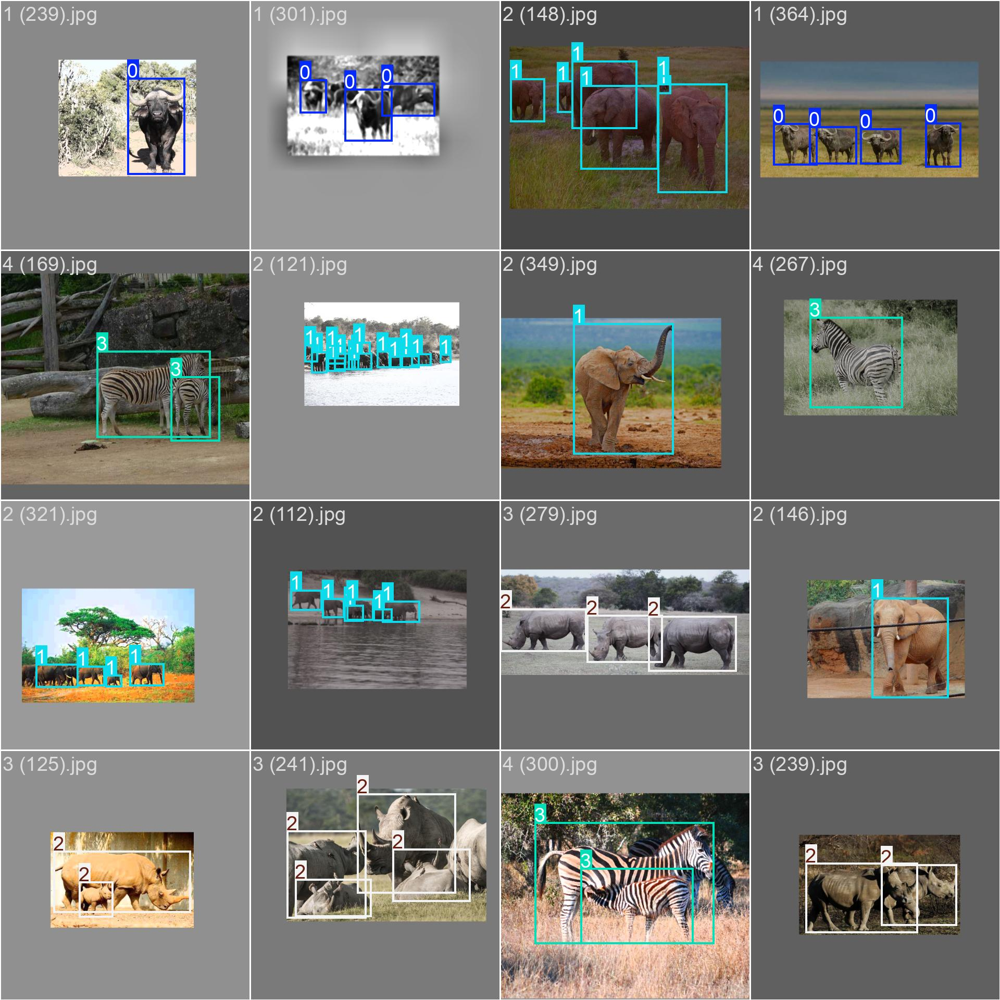

In [ ]:
mostrar_arquivos(pasta_treino, 'train_batch*.jpg', largura=750)

**O que observar:**

- Cada quadro é um **mosaico** de pedaços de 4 fotos. Assim a rede vê animais em escalas, posições e contextos variados, e animais cortados pela borda.
- As **caixas acompanham** as transformações: o rótulo continua certo mesmo depois do recorte.
- Algumas imagens estão **espelhadas** (`fliplr=0.5`) ou com cores alteradas.
- **Use isto para conferir os rótulos do seu dataset:** se aparecer caixa no lugar errado ou objeto sem caixa, o problema está na anotação.

### 6.2 O `labels.jpg`

Um retrato das **caixas anotadas no treino**: quantas há de cada classe, onde ficam os centros na imagem e qual a largura e a altura das caixas.

labels.jpg


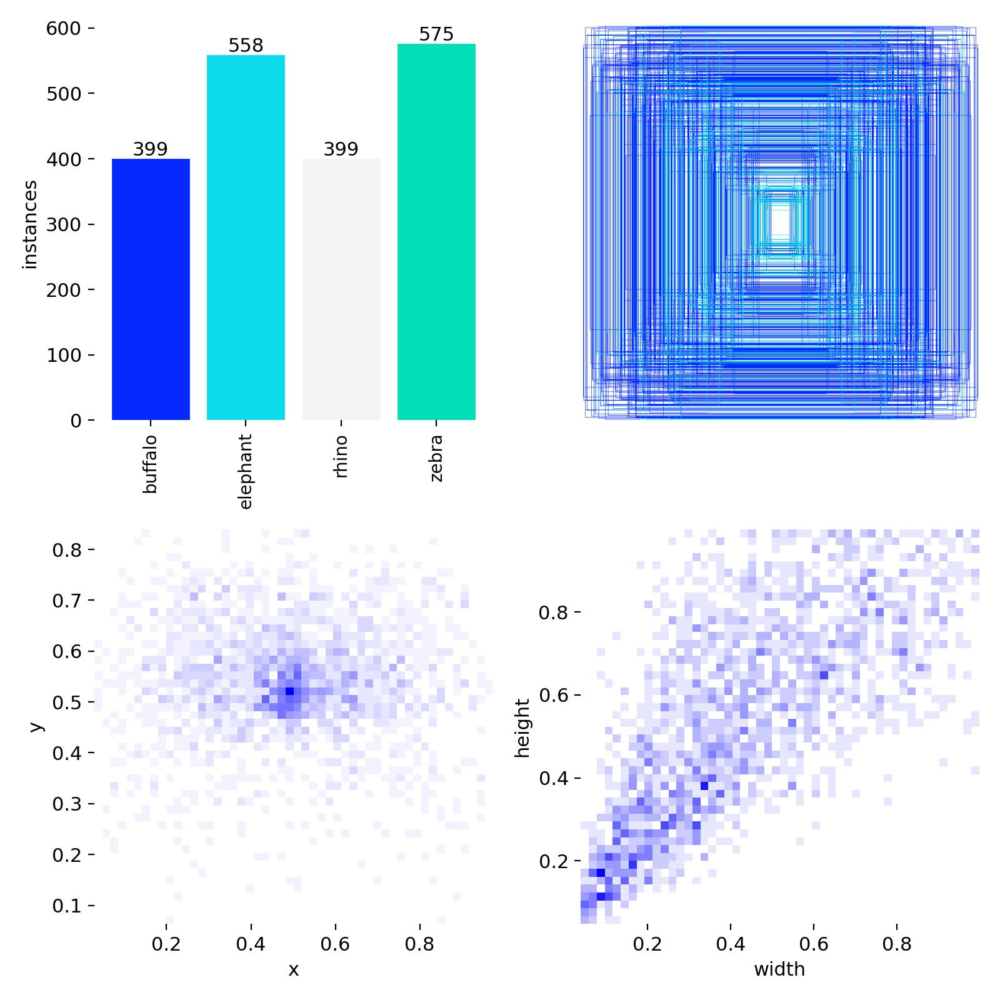

In [ ]:
mostrar_arquivos(pasta_treino, 'labels.jpg', largura=650)

**O que observar:** o gráfico de barras é a contagem de caixas por classe (a mesma da etapa 1.5). Os gráficos de `x`/`y` mostram onde os centros ficam; os de `width`/`height`, o tamanho das caixas. Aqui muitas caixas são grandes, porque os animais costumam ocupar boa parte da foto. **No seu dataset, caixas muito pequenas** são um alerta: pode valer um `imgsz` maior.

### 6.3 Os argumentos usados

Todos os argumentos do treino estão no `args.yaml`, inclusive os que não escrevemos:

In [ ]:
args = yaml.safe_load(open(pasta_treino / 'args.yaml'))

treino = ['model', 'data', 'epochs', 'imgsz', 'batch', 'patience', 'seed', 'optimizer', 'lr0', 'lrf', 'warmup_epochs', 'pretrained']
aumento = ['mosaic', 'close_mosaic', 'fliplr', 'flipud', 'hsv_h', 'hsv_s', 'hsv_v', 'scale', 'translate', 'degrees', 'mixup']

print('TREINO')
for k in treino:
    if k in args: print(f'  {k:14s} = {args[k]}')
print('\nAUMENTO DE DADOS')
for k in aumento:
    if k in args: print(f'  {k:14s} = {args[k]}')

TREINO
  model          = yolo26n.pt
  data           = african-wildlife.yaml
  epochs         = 20
  imgsz          = 640
  batch          = 32
  patience       = 10
  seed           = 0
  optimizer      = auto
  lr0            = 0.01
  lrf            = 0.01
  warmup_epochs  = 3.0
  pretrained     = True

AUMENTO DE DADOS
  mosaic         = 1.0
  close_mosaic   = 10
  fliplr         = 0.5
  flipud         = 0.0
  hsv_h          = 0.015
  hsv_s          = 0.7
  hsv_v          = 0.4
  scale          = 0.5
  translate      = 0.1
  degrees        = 0.0
  mixup          = 0.0


| Argumento | O que faz |
| --- | --- |
| `mosaic` | probabilidade de montar o mosaico de 4 imagens (1.0 = sempre) |
| `close_mosaic` | em quantas épocas finais o mosaico é desligado, para o modelo terminar vendo imagens normais |
| `fliplr`, `flipud` | probabilidade de espelhar na horizontal e na vertical |
| `hsv_h`, `hsv_s`, `hsv_v` | variações aleatórias de matiz, saturação e brilho |
| `scale`, `translate`, `degrees` | ampliar ou reduzir, deslocar, girar |
| `mixup` | probabilidade de misturar duas imagens por transparência |

Repare em `optimizer` e `lr0`: com `optimizer=auto`, o `lr0` que aparece aqui não foi o usado.

---
## 7. A validação

### 7.1 Real × previsto

A YOLO salva batches da **validação** em pares: `val_batch*_labels.jpg` mostra as caixas **anotadas**, e `val_batch*_pred.jpg` mostra **as mesmas imagens** com as caixas **previstas** e a confiança de cada uma. Compare os dois, imagem por imagem.

ANOTADO: val_batch0_labels.jpg


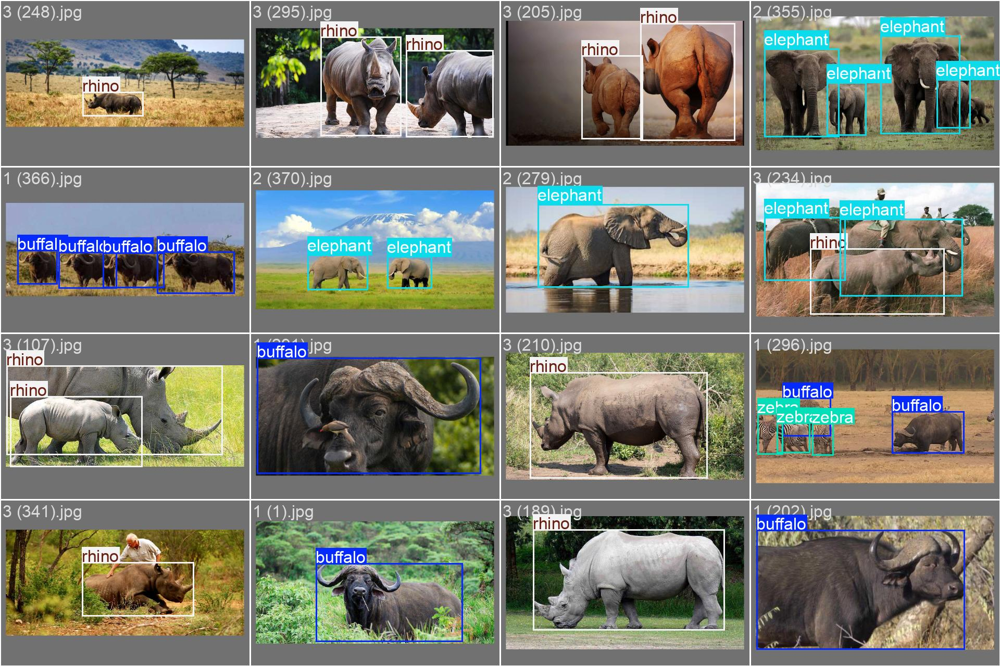

PREVISTO: val_batch0_pred.jpg


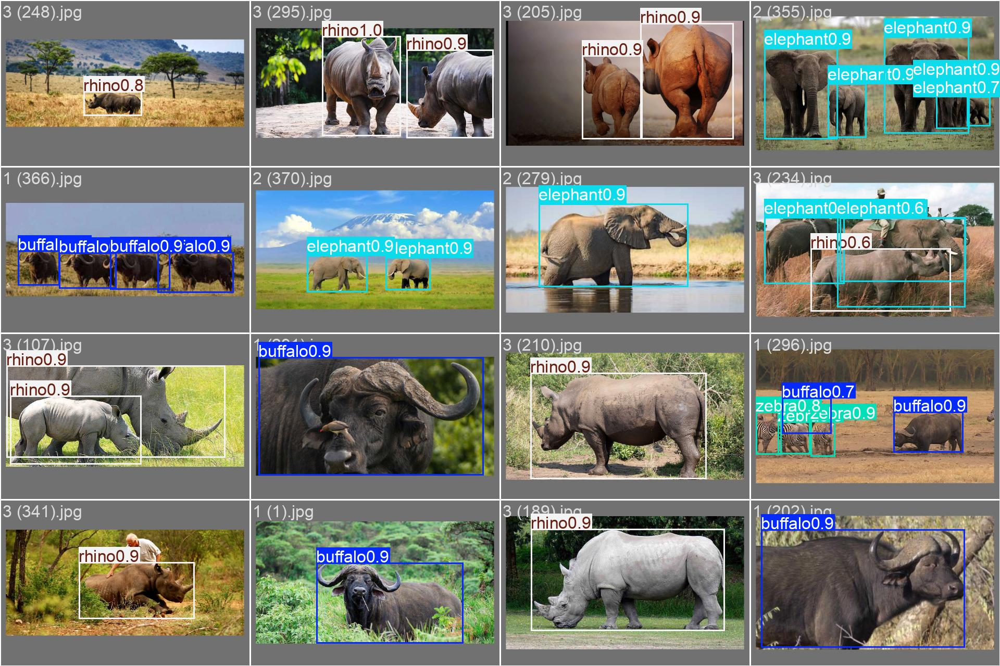

ANOTADO: val_batch1_labels.jpg


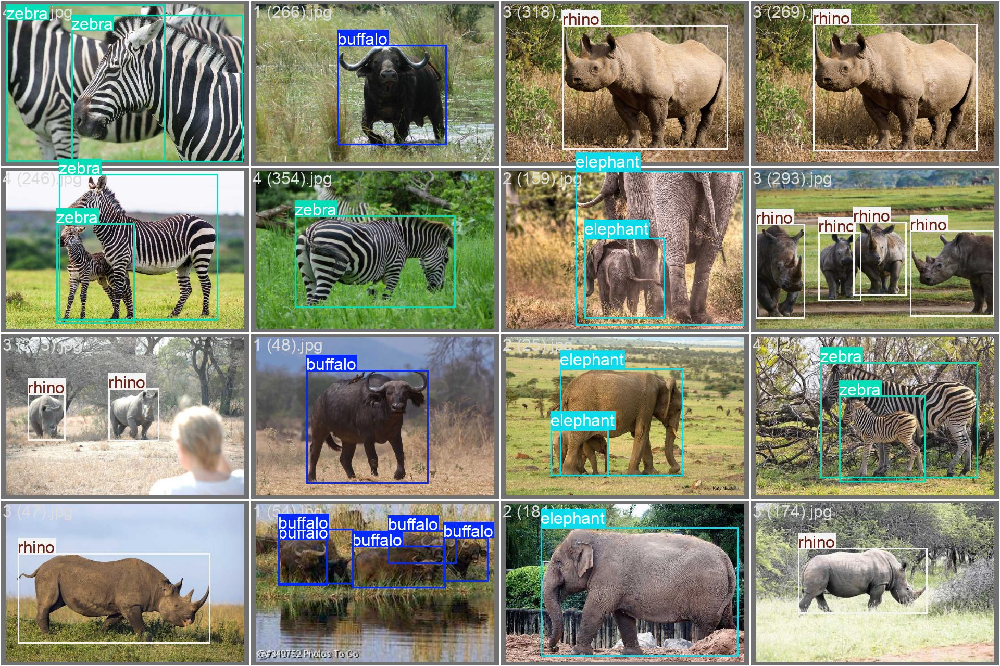

PREVISTO: val_batch1_pred.jpg


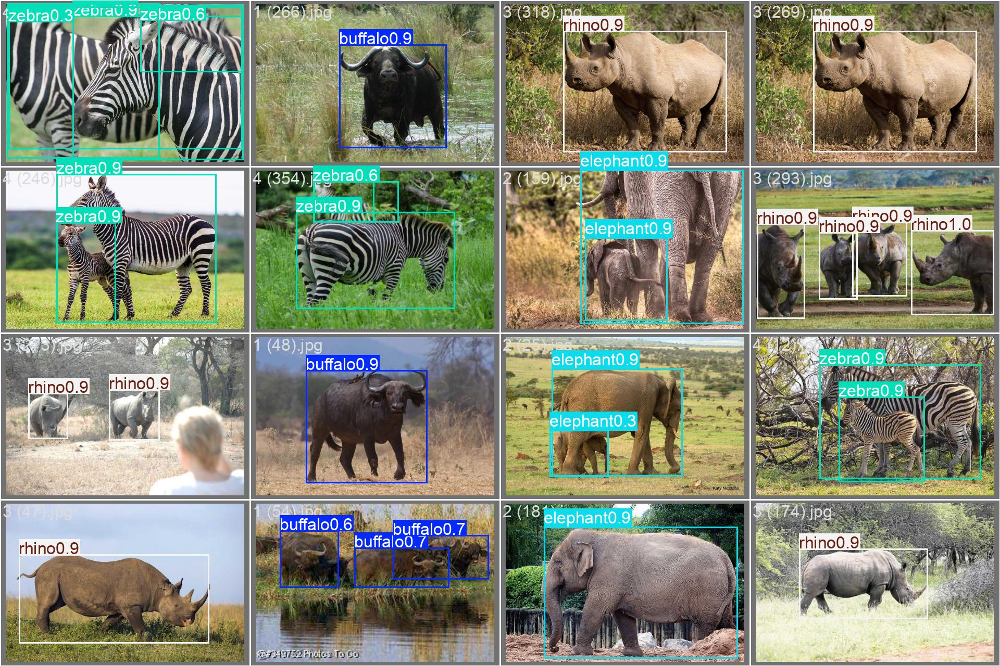

In [ ]:
for rotulos in sorted(pasta_treino.glob('val_batch*_labels.jpg'))[:2]:
    previsoes = pasta_treino / rotulos.name.replace('_labels', '_pred')
    print('ANOTADO:', rotulos.name)
    display(MostrarImagem(filename=str(rotulos), width=750))
    if previsoes.exists():
        print('PREVISTO:', previsoes.name)
        display(MostrarImagem(filename=str(previsoes), width=750))

**O que observar:** procure os três tipos de resultado da aula. **Acertos**: caixa com a classe certa sobre o animal. **Falsos positivos**: caixa onde não há animal, com a classe errada ou repetida. **Falsos negativos**: animal anotado que ficou sem caixa, muitas vezes os pequenos, cortados na borda ou escondidos atrás de outro.

### 7.2 As curvas de precisão × recall e de F1

O `BoxPR_curve.png` traz a curva **precisão × recall** de cada classe: a **área sob a curva é o AP** da classe, e a legenda mostra esse valor (com IoU 0,50). A linha grossa é a média de todas as classes, o **mAP50**.

O `BoxF1_curve.png` mostra o **F1** conforme o limiar de confiança. O **pico** da curva indica o limiar que melhor equilibra precisão e recall.

BoxPR_curve.png


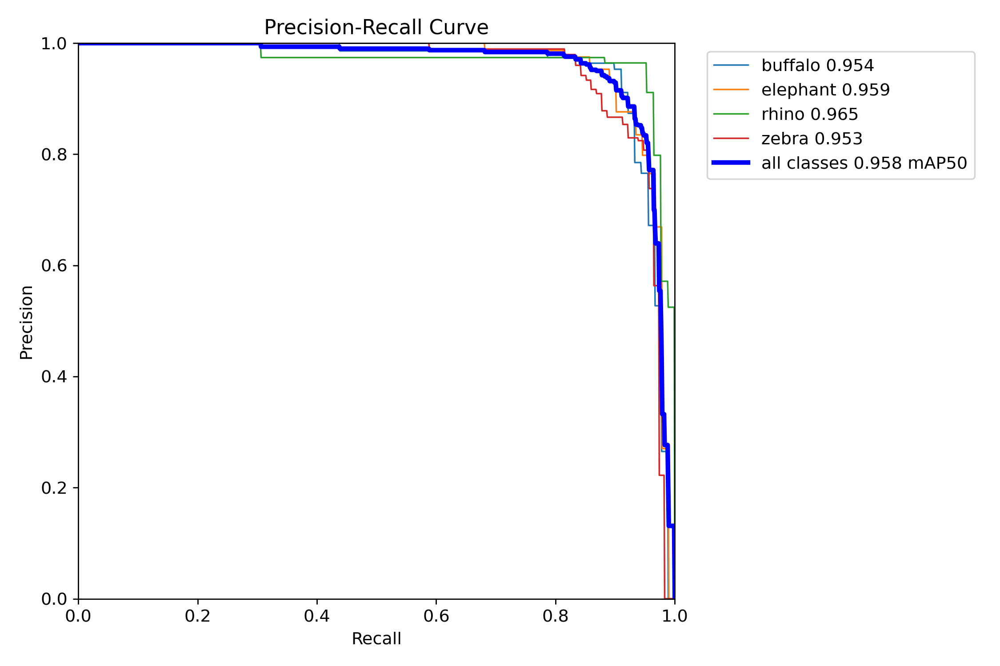

BoxF1_curve.png


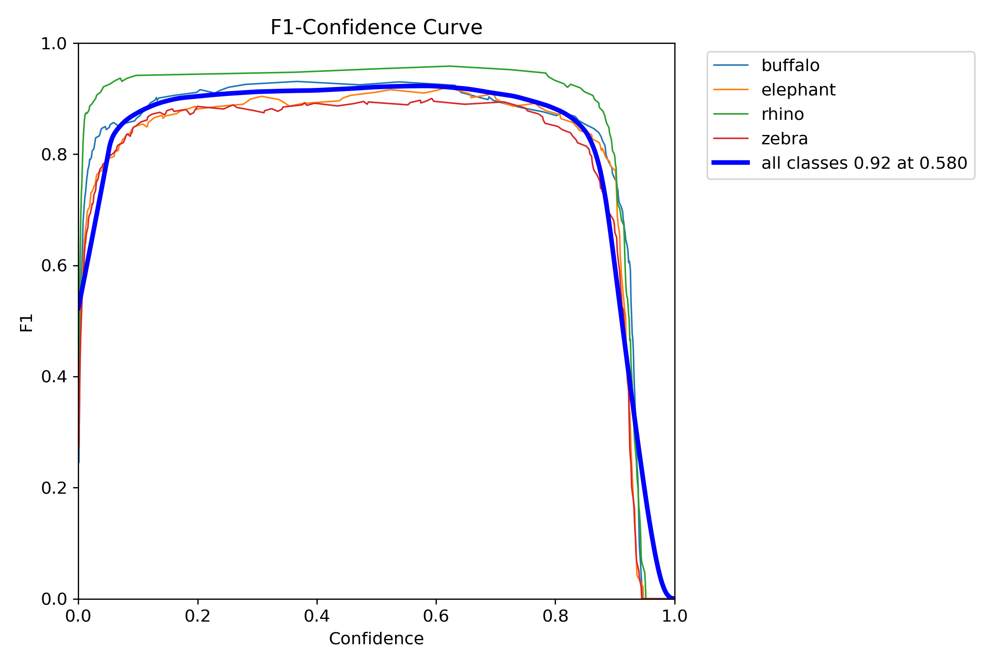

In [ ]:
mostrar_arquivos(pasta_treino, 'BoxPR_curve.png', largura=650)
mostrar_arquivos(pasta_treino, 'BoxF1_curve.png', largura=650)

**O que observar:** qual classe tem a curva mais baixa, isto é, o menor AP? Em geral é uma das que **não estavam no COCO** (búfalo ou rinoceronte), ou a que mais se parece com outra. Na curva F1, em que confiança fica o pico? Compare com o `conf=0.25` que a predição usa por padrão.

### 7.3 A matriz de confusão

Na detecção, cada célula da matriz conta **caixas**, não imagens. Na validação, a YOLO tenta casar cada caixa prevista com uma caixa anotada (IoU ≥ 0,45). Cada caixa termina num destes lugares:

| Situação | Onde cai | Tipo de erro |
| --- | --- | --- |
| caixa prevista casou com uma anotada **da mesma classe** | diagonal | acerto |
| caixa prevista casou com uma anotada **de outra classe** | fora da diagonal, entre as classes | troca (ex.: búfalo previsto como rinoceronte) |
| caixa prevista **sem nenhuma anotada** por perto | **coluna background** | falso positivo: o modelo inventou um animal |
| caixa anotada **sem nenhuma prevista** por perto | **linha background** | falso negativo: o modelo perdeu um animal |

- **Colunas** = classe **real** (`True`); **linhas** = classe **prevista** (`Predicted`).
- O canto **background × background** fica sempre vazio: na detecção não existe verdadeiro negativo, porque não se contam "os lugares sem animal".

A YOLO salva a mesma matriz de duas formas: em **contagens** (`confusion_matrix.png`) e **normalizada** (`confusion_matrix_normalized.png`). As duas contam histórias bem diferentes, então vamos ler uma de cada vez.


confusion_matrix.png


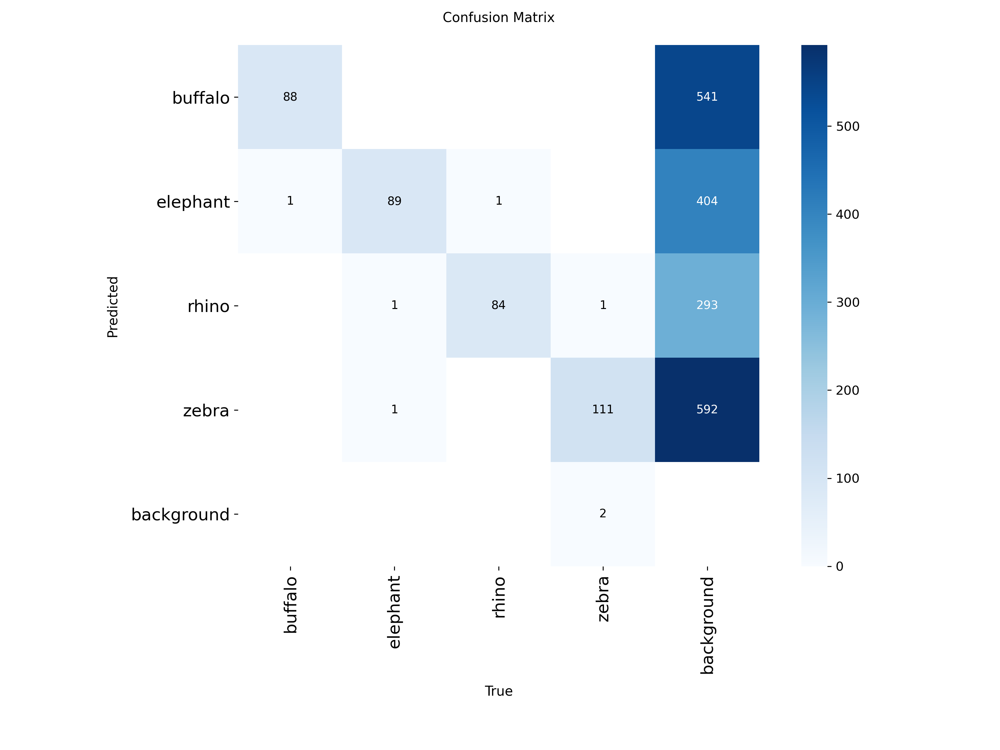

confusion_matrix_normalized.png


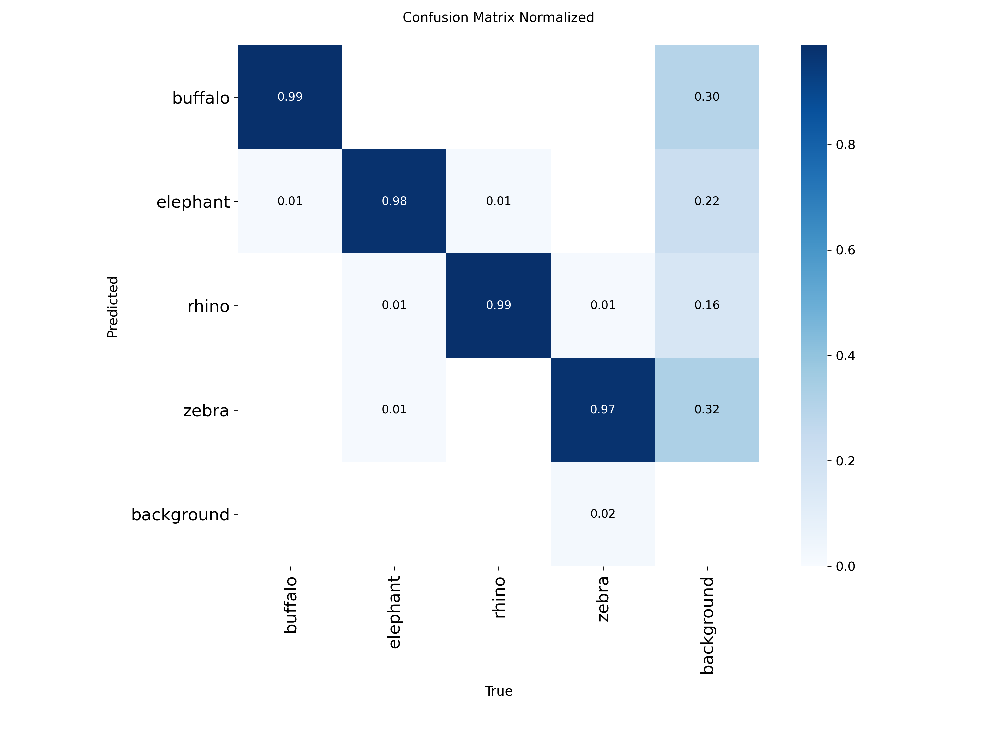

In [ ]:
mostrar_arquivos(pasta_treino, 'confusion_matrix*.png', largura=620)

#### Lendo a matriz em contagens

Olhe primeiro a **coluna background**. Ela costuma ter números **enormes**: num treino de referência desta prática, cerca de **3.000 falsos positivos** contra uns **360 acertos** na diagonal. À primeira vista, o modelo parece péssimo: inventaria quase dez animais para cada um que acerta.

Mas a tabela por classe (etapa 7.5) mostra **precisão perto de 0,95**. Como as duas coisas podem ser verdade?

**A matriz é montada com o limiar de confiança da validação, `conf=0.001`.** Na validação, praticamente **toda** caixa que a rede sugere entra na conta, inclusive as que ela própria acha que têm 0,1% de chance de ser um animal. Esse limiar baixíssimo é necessário para o **mAP**, que varre todos os limiares para desenhar a curva precisão × recall (etapa 7.2). Só que ele enche a coluna do fundo de caixas que **nunca apareceriam** quando você usa o modelo, porque a predição usa `conf=0.25`.

Já o **P** e o **R** da tabela são calculados no limiar que dá o **melhor F1** (o pico do `BoxF1_curve.png`), onde essas caixas fracas já foram descartadas.

**Moral:** nas contagens, a **coluna background** reflete mais o limiar `0.001` do que a qualidade do modelo. As **outras** células (diagonal, trocas e a linha background) são confiáveis, porque caixas tão fracas quase nunca casam com um animal real.

#### Lendo a matriz normalizada

A normalizada **divide cada coluna pela soma da própria coluna**: cada coluna soma 1. Como as colunas são a classe **real**, cada coluna responde: *"dos animais desta classe, para onde eles foram?"*

**Nas colunas das classes**, isso é muito útil. Exemplo do treino de referência, coluna **buffalo**: havia 89 búfalos reais; 82 foram previstos como búfalo, 3 como elefante e 4 como rinoceronte.

| Coluna buffalo | contagem | normalizada |
| --- | --- | --- |
| previsto buffalo | 82 | 82 ÷ 89 = **0,92** |
| previsto elephant | 3 | 3 ÷ 89 = 0,03 |
| previsto rhino | 4 | 4 ÷ 89 = 0,04 |
| previsto background | 0 | 0,00 |

- A **diagonal** vira a fração de animais encontrados com a classe certa: é um **recall por classe** (com o limiar 0.001 e IoU 0,45).
- As células **abaixo e acima** da diagonal mostram **com quem** cada classe é confundida, já em proporção. Isso permite comparar classes com quantidades diferentes de animais, o que as contagens não deixam fazer direito (há 114 zebras e 85 rinocerontes, por exemplo).
- A **linha background** mostra a fração de animais de cada classe que o modelo **perdeu**.

**Na coluna background, a normalizada engana.** Essa coluna também é dividida pela própria soma, que é o **total de falsos positivos**. No exemplo: 1.010 + 573 + 435 + 977 = 2.995, e a coluna vira 0,34 / 0,19 / 0,15 / 0,33. Esses números **não** dizem que 34% das caixas de búfalo estão erradas. Dizem só que, **entre as caixas inventadas**, 34% receberam o nome "búfalo". E, ao dividir, a normalizada **apaga o tamanho** do problema: 3 falsos positivos ou 3.000 viram a mesma coluna somando 1.

#### Por que a diagonal não bate com o recall da tabela?

No treino de referência, a diagonal do búfalo deu **0,92**, mas o **R** do búfalo na tabela da etapa 7.5 deu **0,85**. Os dois são "recall", mas medidos de jeitos diferentes:

| | Matriz | Tabela (`m.box.r`) |
| --- | --- | --- |
| limiar de confiança | `0.001` (quase tudo entra) | o do melhor F1 (mais alto) |
| IoU para contar acerto | 0,45 | 0,50 |

Com mais caixas e uma exigência de IoU menor, a matriz encontra mais animais. **Use a tabela para os números oficiais e a matriz para entender para onde vão os erros.**

#### A mesma matriz no limiar de uso

Para ver a matriz como ela fica **quando o modelo é usado**, validamos de novo com `conf=0.25`, o limiar padrão da predição, e comparamos com o `conf=0.001`. A célula resume cada matriz em cinco números:

In [ ]:
melhor = YOLO(pasta_treino / 'weights' / 'best.pt')

def resumo_matriz(mat):
    # mat[prevista, real]; a última linha e a última coluna são o fundo (background)
    n = mat.shape[0] - 1
    return {'acertos (diagonal)': int(np.trace(mat[:n, :n])),
            'trocas entre classes': int(mat[:n, :n].sum() - np.trace(mat[:n, :n])),
            'FP (coluna do fundo)': int(mat[:n, n].sum()),
            'FN (linha do fundo)': int(mat[n, :n].sum()),
            'animais anotados': int(mat[:, :n].sum())}

linhas, pastas = [], {}
for conf in [0.001, 0.25]:
    v = melhor.val(data=DATASET, imgsz=640, conf=conf, verbose=False,
                   project='aula_yolo', name=f'matriz_conf_{conf}', exist_ok=True)
    pastas[conf] = Path(v.save_dir)
    linhas.append({'conf': conf, **resumo_matriz(v.confusion_matrix.matrix)})

display(pd.DataFrame(linhas).set_index('conf'))

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1616.3±1260.6 MB/s, size: 99.8 KB)
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 62.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.3it/s 3.5s
                   all        225        379      0.951      0.886      0.958       0.81
Speed: 1.9ms preprocess, 6.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/aula_yolo/matriz_conf_0.001
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2483.8±1108.9 MB/s,

,acertos (diagonal),trocas entre classes,FP (coluna do fundo),FN (linha do fundo),animais anotados
conf,,,,,
0.001,371,6,1852,2,379
0.250,351,4,37,24,379


E as duas matrizes com `conf=0.25`:

confusion_matrix.png


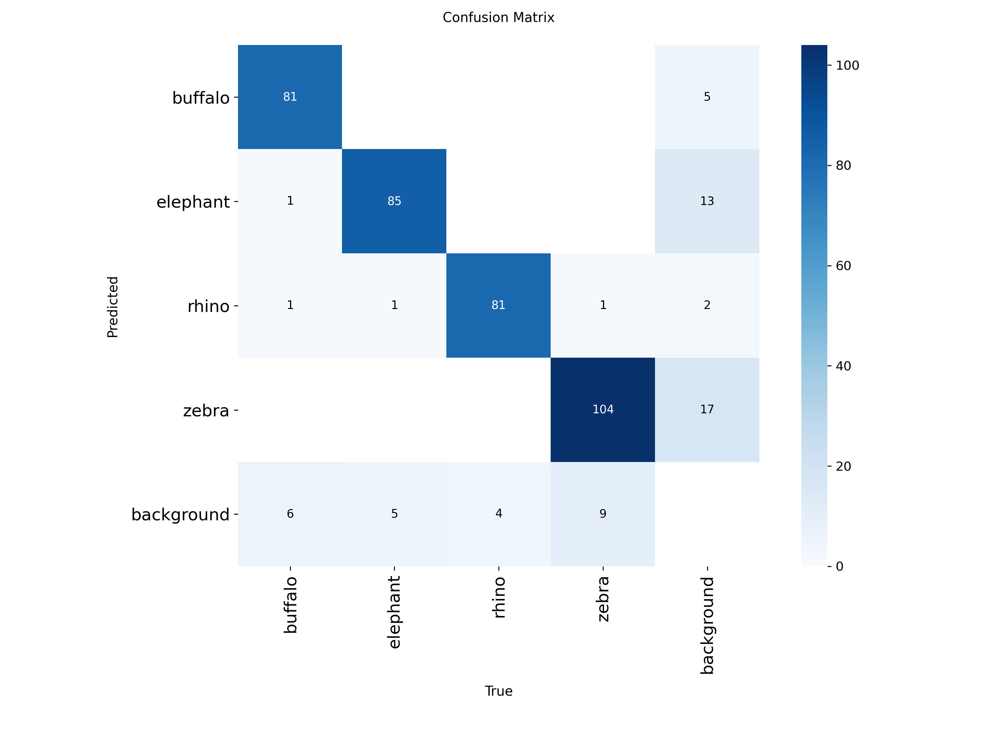

confusion_matrix_normalized.png


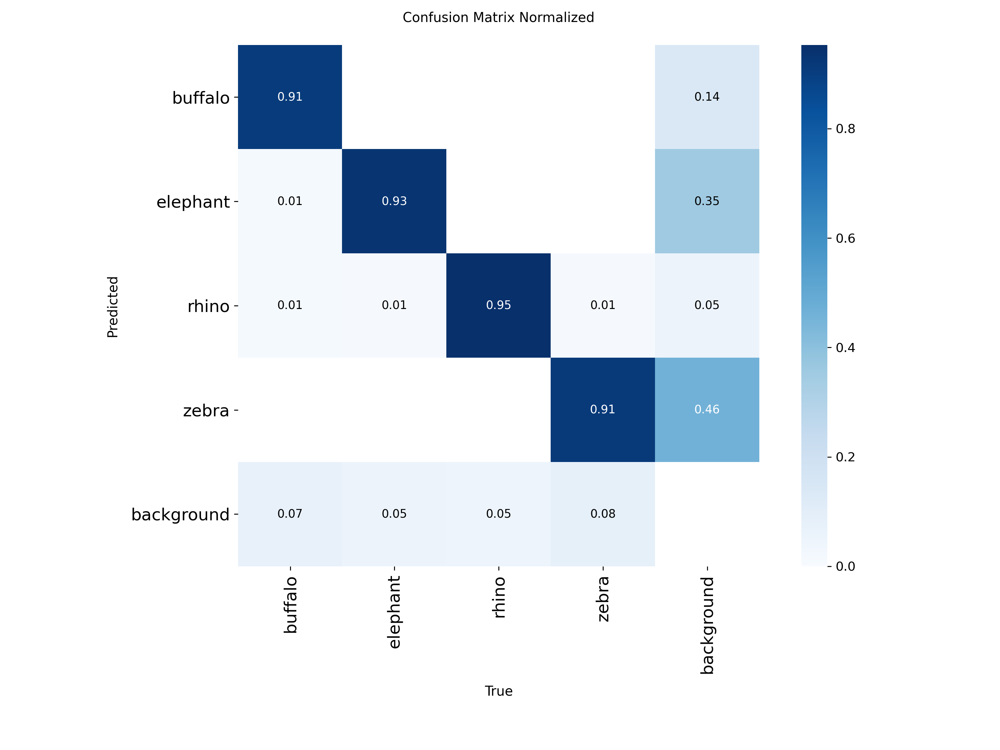

In [ ]:
mostrar_arquivos(pastas[0.25], 'confusion_matrix*.png', largura=620)

**O que observar:**

- Os **falsos positivos despencam**, de milhares para algumas dezenas. Quase todas aquelas caixas tinham confiança abaixo de 0,25.
- Os **falsos negativos sobem um pouco**: alguns animais só tinham caixas fracas e agora ficam de fora. A diagonal cai um pouco pelo mesmo motivo.
- É a troca entre **precisão e recall** da aula, vista na matriz: subir o `conf` limpa a coluna do fundo e enche um pouco a linha do fundo.
- Repare que **a soma de cada coluna de classe não muda** (os animais anotados são os mesmos). O que muda é para onde eles vão: diagonal, outra classe ou fundo.
- **Nos relatórios, mostrem a matriz no `conf` que vocês vão usar** e digam qual foi. A matriz salva no treino, com `conf=0.001`, serve para estudar as trocas, não para contar falsos positivos.

**Para discutir:**

1. Qual classe mais se confunde com qual? A confusão faz sentido visualmente (búfalo e rinoceronte são escuros, grandes e aparecem em ambientes parecidos)?
2. O modelo erra mais **trocando classes** ou **perdendo** e **inventando** animais? Qual desses erros é mais grave numa aplicação real, como contar animais numa reserva?
3. Com `conf=0.25`, os falsos positivos que sobraram se concentram em alguma classe? Olhe algumas imagens da etapa 7.1 para ver o que o modelo está confundindo com animal.

### 7.4 `best.pt` × `last.pt`

O `best.pt` é a melhor época na validação; o `last.pt`, a última. Avaliamos os dois no conjunto de **validação** com o `.val()`. Os resultados ficam em `m.box`:

| Atributo | Métrica |
| --- | --- |
| `m.box.mp` | precisão média (P) |
| `m.box.mr` | recall médio (R) |
| `m.box.map50` | mAP50 |
| `m.box.map` | mAP50-95 |

In [ ]:
linhas = []
for nome in ['best.pt', 'last.pt']:
    m = YOLO(pasta_treino / 'weights' / nome).val(data=DATASET, imgsz=640, verbose=False, plots=False)
    p, r = m.box.mp, m.box.mr
    linhas.append({'modelo': nome, 'P': p, 'R': r, 'F1': 2 * p * r / max(p + r, 1e-9),
                   'mAP50': m.box.map50, 'mAP50-95': m.box.map})

display(pd.DataFrame(linhas).set_index('modelo').round(3))

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2354.2±578.6 MB/s, size: 57.6 KB)
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 85.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 7.4it/s 2.0s
                   all        225        379      0.951      0.886      0.958       0.81
Speed: 0.7ms preprocess, 3.5ms inference, 0.0ms loss, 1.5ms postprocess per image
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1130.5±913.0 MB/s, size: 24.2 KB)
val: Scanning /content/datasets/african-wildlife/lab

,P,R,F1,mAP50,mAP50-95
modelo,,,,,
best.pt,0.951,0.886,0.918,0.958,0.81
last.pt,0.951,0.886,0.918,0.958,0.81


**O que observar:** se o treino foi até a última época sem early stopping, os dois podem ser iguais ou quase. Se diferirem, o `best.pt` tende a ter o maior mAP50-95 na validação, porque foi escolhido por ela. **O modelo oficial é o `best.pt`.** O F1 não aparece na tabela da YOLO; calculamos a partir de P e R.

### 7.5 As métricas por classe

A média esconde a classe problemática. O `.val()` também devolve as métricas **de cada classe**:

| Atributo | Por classe |
| --- | --- |
| `m.box.p`, `m.box.r`, `m.box.f1` | precisão, recall e F1 |
| `m.box.ap50` | AP com IoU 0,50 |
| `m.box.maps` | AP de 0,50 a 0,95 |
| `m.box.ap_class_index` | o índice da classe de cada posição |

In [ ]:
melhor = YOLO(pasta_treino / 'weights' / 'best.pt')
m = melhor.val(data=DATASET, imgsz=640, verbose=False, plots=False)

idx = list(m.box.ap_class_index)
tabela = pd.DataFrame({
    'P': m.box.p,
    'R': m.box.r,
    'F1': m.box.f1,
    'AP50': m.box.ap50,
    'AP50-95': [m.box.maps[i] for i in idx],
}, index=[legivel(NOMES[i]) for i in idx])
tabela.index.name = 'classe'
tabela.loc['média'] = tabela.mean()
display(tabela.round(3))

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1758.6±1520.9 MB/s, size: 57.5 KB)
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 78.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 7.4it/s 2.0s
                   all        225        379      0.951      0.886      0.958       0.81
Speed: 0.9ms preprocess, 3.2ms inference, 0.0ms loss, 1.4ms postprocess per image


,P,R,F1,AP50,AP50-95
classe,,,,,
búfalo,0.959,0.876,0.916,0.952,0.805
elefante,0.942,0.891,0.916,0.960,0.806
rinoceronte,0.946,0.953,0.950,0.966,0.860
zebra,0.957,0.825,0.886,0.952,0.768
média,0.951,0.886,0.917,0.958,0.810


**Como ler:**

- **P baixa** numa classe: o modelo desenha caixas dela onde não deveria (ou troca outra classe por ela).
- **R baixo**: o modelo deixa passar animais dessa classe.
- **AP50 alto e AP50-95 baixo**: acha o animal, mas a caixa não fica justa.
- A linha **média** dos APs é o mAP: compare com a tabela da etapa 7.4.

### 7.6 O teste, uma única vez

Até aqui tudo foi feito na validação, que também foi usada para escolher o `best.pt`, então ela tende a ser um pouco otimista. O **teste** é a prova final: avaliamos o modelo escolhido **uma única vez**, com `split="test"`.

In [ ]:
if info.get('test'):
    t = melhor.val(data=DATASET, imgsz=640, split='test', verbose=False, plots=False)
    p, r = t.box.mp, t.box.mr
    display(pd.DataFrame([
        {'conjunto': 'validação', 'P': m.box.mp, 'R': m.box.mr, 'F1': 2 * m.box.mp * m.box.mr / max(m.box.mp + m.box.mr, 1e-9),
         'mAP50': m.box.map50, 'mAP50-95': m.box.map},
        {'conjunto': 'teste', 'P': p, 'R': r, 'F1': 2 * p * r / max(p + r, 1e-9),
         'mAP50': t.box.map50, 'mAP50-95': t.box.map},
    ]).set_index('conjunto').round(3))
else:
    print('Este dataset não tem conjunto de teste.')

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1392.3±993.5 MB/s, size: 100.2 KB)
val: Scanning /content/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 1.9Kit/s 0.1s
val: New cache created: /content/datasets/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.6it/s 3.3s
                   all        227        375      0.951      0.936      0.976      0.843
Speed: 1.6ms preprocess, 4.9ms inference, 0.0ms loss, 2.6ms postprocess per image


,P,R,F1,mAP50,mAP50-95
conjunto,,,,,
validação,0.951,0.886,0.918,0.958,0.810
teste,0.951,0.936,0.944,0.976,0.843


**Para pensar:** a validação e o teste deram números parecidos? Pequenas diferenças são normais com pouco mais de 200 imagens em cada conjunto. **O número que vai na apresentação é o do teste.**

---
## 8. Prever imagens novas

### 8.1 As caixas de cada imagem

Para usar o modelo, basta chamá-lo com uma ou mais imagens. Cada resultado traz `boxes`, uma entrada por caixa encontrada, com:

- `boxes.cls`: o índice da classe (o nome está em `r.names[...]`);
- `boxes.conf`: a confiança (de 0 a 1);
- `boxes.xyxy`: os cantos da caixa em pixels (x1, y1, x2, y2);
- `boxes.xywhn`: centro, largura e altura normalizados, o mesmo formato do `.txt`.

Usamos imagens do **teste**, que o modelo nunca viu.

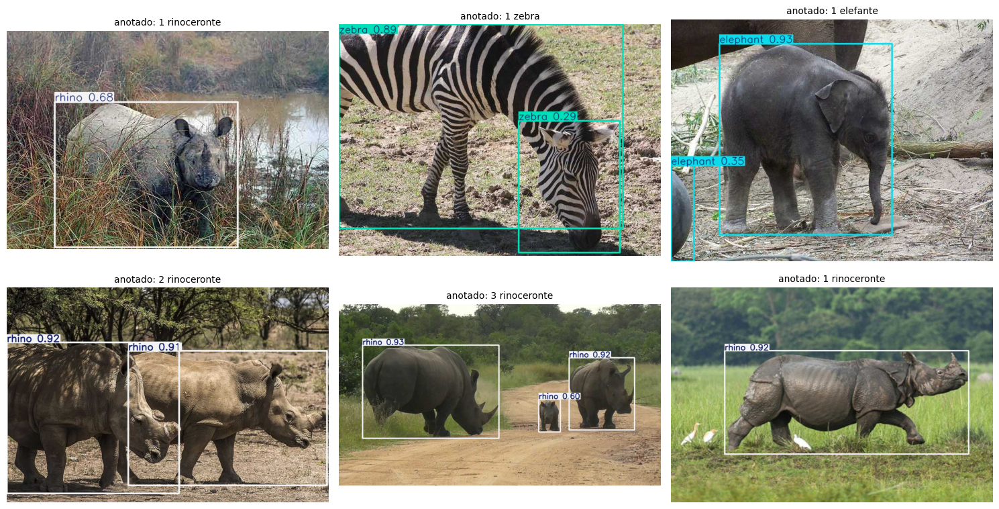

In [ ]:
imagens_teste = imagens_da_pasta(Path(info['test'] or info['val']))
amostra = random.sample(imagens_teste, 6)
resultados = melhor(amostra, imgsz=640, conf=0.25, verbose=False)

titulos = []
for caminho, r in zip(amostra, resultados):
    real = Counter(legivel(NOMES[c]) for c, *_ in ler_rotulo(rotulo_da_imagem(caminho)))
    titulos.append('anotado: ' + ', '.join(f'{v} {k}' for k, v in real.items()))
mostrar_resultados(resultados, titulos, colunas=3)

E as caixas de uma imagem, uma por linha:

In [ ]:
r = resultados[0]
print('Imagem:', amostra[0].name, f'· {len(r.boxes)} caixas\n')
for caixa in r.boxes:
    classe = legivel(r.names[int(caixa.cls)])
    x1, y1, x2, y2 = caixa.xyxy[0].tolist()
    print(f'{classe:12s} confiança {float(caixa.conf):.2f} · cantos ({x1:.0f}, {y1:.0f}) e ({x2:.0f}, {y2:.0f})')

Imagem: 3 (8).jpg · 1 caixas

rinoceronte  confiança 0.68 · cantos (90, 133) e (431, 403)


### 8.2 O efeito do limiar de confiança

O `conf` decide quais caixas aparecem. Vamos prever a mesma imagem com três limiares:

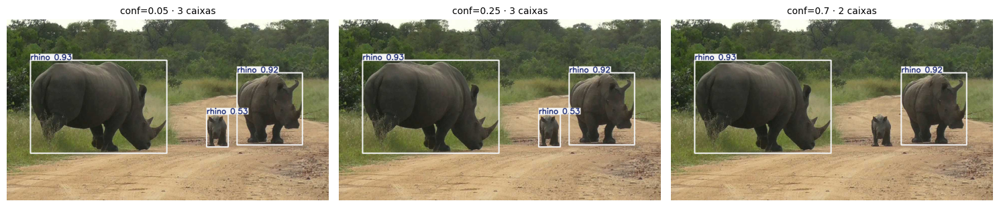

Animais anotados nesta imagem: 3


In [ ]:
imagem = max(amostra, key=lambda p: len(ler_rotulo(rotulo_da_imagem(p))))     # a com mais animais
limiares = [0.05, 0.25, 0.70]
resultados = [melhor(imagem, imgsz=640, conf=c, verbose=False)[0] for c in limiares]
titulos = [f'conf={c} · {len(r.boxes)} caixas' for c, r in zip(limiares, resultados)]
mostrar_resultados(resultados, titulos, colunas=3)
print('Animais anotados nesta imagem:', len(ler_rotulo(rotulo_da_imagem(imagem))))

**O que observar:** com `conf` baixo aparecem mais caixas, inclusive erradas: **mais recall, menos precisão**. Com `conf` alto ficam só as caixas de que o modelo tem certeza, e algum animal pode sumir: **mais precisão, menos recall**. É a curva da etapa 7.2 na prática. O `conf` se escolhe no uso, conforme o que custa mais caro no seu problema: perder um objeto ou dar um alarme falso.

### 8.3 Salvar as imagens com as caixas

O `r.save()` grava a imagem com as caixas desenhadas:

In [ ]:
saida = Path('previsoes')
saida.mkdir(exist_ok=True)
for i, r in enumerate(melhor(amostra, imgsz=640, conf=0.25, verbose=False)):
    r.save(filename=str(saida / f'pred_{i}.jpg'))
print('Imagens salvas em', saida.resolve())

Imagens salvas em /content/previsoes


---
## 9. Receita para o seu dataset

Para usar os seus dados, você repete **este mesmo notebook**. O que muda:

**Antes**, prepare o dataset no formato da etapa 1:

- [ ] Todos os objetos anotados, com caixas justas, exportados no **formato YOLO** (classes a partir de 0).
- [ ] `images/` e `labels/` com as mesmas subpastas `train/`, `val/` e, de preferência, `test/`.
- [ ] Cada imagem com um `.txt` **do mesmo nome** (imagens sem objeto podem ficar sem `.txt`).
- [ ] Divisão feita por você e **por grupo** se as fotos forem parentes (mesmo prédio, mesmo vídeo, mesmo paciente).
- [ ] Um `data.yaml` com `path`, `train`, `val`, `test` e `names`.
- [ ] Tudo compactado num `.zip` e enviado para o seu Google Drive.

Um `data.yaml` de exemplo, para o dataset descompactado em `/content/meu_dataset`:

```yaml
path: /content/meu_dataset
train: images/train
val: images/val
test: images/test
names:
  0: capacete
  1: sem_capacete
```

**No Colab:**

1. Execute a etapa 0 (preparação), com a **GPU ligada**.
2. Traga o dataset para o Colab, montando o Drive e descompactando (a célula abaixo).
3. Na etapa 1, troque a linha para `DATASET = "/content/meu_dataset/data.yaml"`.
4. Na etapa 3, ajuste o que fizer sentido: `fliplr` (espelhar faz sentido no seu problema?), `epochs`, `batch` e, para objetos pequenos, `imgsz`.
5. Execute o resto do notebook, **na ordem**, e leia os resultados como fizemos aqui. Na etapa 2, o modelo pré-treinado provavelmente não vai conhecer as suas classes: é esperado.